# **Micromobility Infrastructure Planner for Low-Stress and Accessible Networks (MicromobilityPLAN)**

This is a tool for growing low-stress bike networks for micromobility that analyzes OpenStreetMap (OSM) data to identify bike infrastructure, assign stress levels based on road attributes, and recommend targeted upgrades.

# **Notebook and Folder Setup**

## Packages & Libraries

In [ ]:
# Install required packages (missing from CoLab)
!pip install contextily osmnx

In [ ]:
# Load libraries, settings and data

# Standard Libraries
import json
import pickle
import warnings
from datetime import datetime
import os
import itertools
from itertools import combinations
import re

# Geospatial Libraries
import geopandas as gpd
import shapely
from shapely.ops import split, unary_union, linemerge
from shapely.geometry import LineString, MultiPoint, Point, MultiLineString
import osmnx as ox
import networkx as nx

# Visualization Libraries
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
from matplotlib import cm, colors
import matplotlib.patches as mpatches
import contextily as cx
from IPython.display import Image, display, HTML

# Data Handling
import numpy as np
import pandas as pd
import math
import yaml

# Suppress warnings for a cleaner output
warnings.filterwarnings("ignore")

## Folders

In [ ]:
#Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Define base paths
project_root = "/content/drive/MyDrive/MicromobilityPLAN"
study_area = "aaaaaaa" # City name, used for folders
study_area_root = os.path.join(project_root, study_area)

# Define subfolders
data_fp = os.path.join(study_area_root, "data")
results_fp = os.path.join(study_area_root, "results")
images_fp = os.path.join(results_fp, "streetview")

os.makedirs(data_fp, exist_ok=True)
os.makedirs(results_fp, exist_ok=True)
os.makedirs(images_fp, exist_ok=True)

The code above sets up the directory structure for MicromobilityPLAN on Google Drive.

*   At the root, a folder named MicromobilityPLAN is created.
*   Inside it, a subfolder is generated for the study area (named after the city).
*   Within the study area folder:
    *   data/ → stores input datasets.
    *   results/ → stores analysis outputs.
        *   streetview/ → nested inside results/, used for saving images (e.g., Google Street View captures).

## Plot Settings

In [ ]:
# Basemap providers
cx_tile_1 = cx.providers.CartoDB.Voyager
cx_tile_2 = cx.providers.CartoDB.Positron

In [ ]:
# Plot resolution setting
plot_res = "low" # Options: "high" or "low"

# Determine renderer format based on resolution
def get_renderer_map(plot_res):
    return "svg" if plot_res == "high" else "png"

renderer_map = get_renderer_map(plot_res)

# Set renderer format (SVG for high quality, PNG for low)
def set_renderer(fmt="svg"):
    matplotlib_inline.backend_inline.set_matplotlib_formats(fmt)

In [ ]:
# Colormap to HEX converter
def convert_cmap_to_hex(cmap_name, n=None):
    cmap = cm.get_cmap(cmap_name, n) if n else cm.get_cmap(cmap_name)
    return [mpl.colors.rgb2hex(cmap(i)) for i in range(cmap.N)]

# Generate color ramps
pink_green_cmap = convert_cmap_to_hex("PiYG", 10)
orange_cmap      = convert_cmap_to_hex("Oranges", 10)
purple_cmap      = convert_cmap_to_hex("Purples", 10)
blue_cmap        = convert_cmap_to_hex("Blues", 10)
red_cmap         = convert_cmap_to_hex("Reds", 10)

# Select specific shades from each colormap
pink, green               = pink_green_cmap[1], pink_green_cmap[-2]
orange, light_orange      = orange_cmap[5], orange_cmap[4]
dark_orange               = orange_cmap[8]
purple, light_purple      = purple_cmap[6], purple_cmap[4]
dark_purple               = purple_cmap[8]
blue, light_blue          = blue_cmap[6], blue_cmap[4]
dark_blue                 = blue_cmap[8]
red, light_red            = red_cmap[6], red_cmap[5]
dark_red                  = red_cmap[8]

In [ ]:
# Plot styling dictionary
pdict = {
    # Color themes
    "base": "black",
    "base2": "grey",
    "emphasis": "darkorange",
    "contrast": "lightblue",

    # Transparency
    "alpha_back": 0.5,
    "alpha_overlay": 0.7,

    # Line and marker sizes
    "line_base": 1,
    "line_emphasis": 3,
    "mark_base": 2,
    "mark_emphasis": 6,

    # Figure dimensions
    "dpi": 300,
    "fsmap": (8, 7),
    "fsbar": (8, 8),

    # Colormaps
    "cmap_diff": "RdBu",
    "cmap_seq": "YlGnBu",
    "cmap_pos": "Blues",
    "cmap_neg": "Reds",

    # OSM visual elements
    "osm_base": purple,
    "osm_nodes": blue,
    "osm_boundary": "black",

    # Infrastructure colors
    "infra_painted": "#1f77b4",
    "infra_buffered": "#2ca02c",
    "infra_protected": "#ff7f0e",
    "infra_sharrow": "#9467bd",
    "infra_none": "#d3d3d3",

    # Basemap providers
    "basemap_primary": cx_tile_2,
    "basemap_secondary": cx_tile_1,

    # Highway classification colors
    "highway_colors": {
        "primary": "#FFD700",
        "secondary": "#228B22",
        "tertiary": "#4682B4",
        "residential": "#87CEEB",
        "unclassified": "#999999",
        "living_street": "#800080",
    },

    # Parking presence
    "parking_colors": {
        True: "#d73027",   # parking present
        False: "#1a9850",  # no parking
    },

    # Stress level styles
    "stress_styles": {
        "low":  {"color": "blue", "linestyle": "solid", "linewidth": 2.5, "label": "Low Stress"},
        "high": {"color": "red",  "linestyle": "solid", "linewidth": 2.5, "label": "High Stress"},
    },

    # Speed bin palette
    "speed_palette": {
        "6–10 mph":  "#4575b4",
        "11–15 mph": "#74add1",
        "16–20 mph": "#66bd63",
        "21–25 mph": "#a6d96a",
        "26–30 mph": "#ffffbf",
        "31–35 mph": "#fdae61",
        "36+ mph":   "#d73027",
        "Unknown":   "#cccccc",
    },

    # Recommended infrastructure upgrades
    "infra_colors": {
        "painted": "#1f77b4",   # blue
        "buffered": "#2ca02c",  # green
        "protected": "#ff7f0e", # orange
        "sharrow": "#9467bd",   # purple
        "none": "#7f7f7f",      # darker gray for distinction
    },
}

In [ ]:
# Utility function to save figures based on resolution setting
def save_fig(fig, filepath, dpi=pdict["dpi"], plot_res="low"):
    if plot_res == "high":
        fig.savefig(filepath + ".svg", dpi=dpi)
    elif plot_res == "low":
        fig.savefig(filepath + ".png", dpi=dpi)
    else:
        print("Invalid plot resolution. Use 'low' or 'high'.")

# **Study Area**

In [ ]:
# Study area metadata
area_name = "Hartford"  # Name for display and plotting
study_crs = "EPSG:26956"       # Project CRS
study_area_poly_fp = os.path.join(data_fp, "study_area_polygon.gpkg")

In [ ]:
# Load polygon geometry
study_area_poly = gpd.read_file(study_area_poly_fp)

# Check and reproject CRS
if study_area_poly.crs is None:
    print("Please assign a CRS to the study area polygon!")
elif study_area_poly.crs != study_crs:
    study_area_poly = study_area_poly.to_crs(study_crs)

# Confirm CRS match
assert study_area_poly.crs == study_crs

# Compute polygon area in square kilometers
area_km2 = study_area_poly.area.values[0] / 1_000_000
print(f"The size of the study area is {area_km2:.2f} km².")

The size of the study area is 46.85 km².


This study area will be used for the analysis:


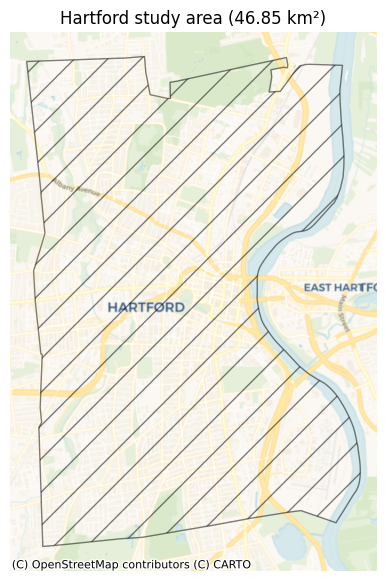

In [ ]:
# Plot the study area
set_renderer(renderer_map)
print("This study area will be used for the analysis:")

fig, ax = plt.subplots(1, figsize=pdict["fsmap"])
study_area_poly.plot(
    ax=ax,
    edgecolor=pdict["base"],
    facecolor='none',
    alpha=pdict["alpha_back"],
    hatch='/'
)
ax.set_axis_off()
cx.add_basemap(ax, crs=study_area_poly.crs, source=pdict["basemap_secondary"])
ax.set_title(f"{area_name} study area ({area_km2:.2f} km²)")

# Save figure to results folder
save_fig(fig, os.path.join(results_fp, "area_size"))

# **Functions**

## OSM Tags

In [ ]:
# Define OSM tags to extract
osm_way_tags = [
    "highway", "maxspeed", "lanes", "oneway", "name", "osmid", "access",
    "cycleway", "cycleway:left", "cycleway:right", "cycleway:both",
    "cycleway:lane", "cycleway:track", "cycleway:buffer",
    "cycleway:left:buffer", "cycleway:right:buffer", "cycleway:both:buffer",
    "cycleway:separation", "cycleway:both:separation","bicycle", "oneway:bicycle",
    "parking:lane:left", "parking:lane:right"
]

# Apply tag settings in OSMnx
ox.settings.use_cache = False
ox.settings.useful_tags_way = osm_way_tags

## Data Functions

In [ ]:
# Clean column names
def clean_col_names(df):
    df.columns = df.columns.str.lower()
    df.columns = [c.replace(":", "_") for c in df.columns]
    return df

In [ ]:
# Clean highway tag
def clean_highway_tag(tag):
    if pd.isna(tag):
        return "unclassified"
    tag = str(tag).lower()
    return tag.replace("_link", "") if "_link" in tag else tag

In [ ]:
def classify_bike_infra(row):
    # Extract core cycleway tags
    c_tags = [
        row.get("cycleway", ""),
        row.get("cycleway_left", ""),
        row.get("cycleway_right", ""),
        row.get("cycleway_both", "")
    ]
    buffers = [
        row.get("cycleway_buffer", ""),
        row.get("cycleway_left_buffer", ""),
        row.get("cycleway_right_buffer", ""),
        row.get("cycleway_both_buffer", "")
    ]
    separations = [
        row.get("cycleway_separation", ""),
        row.get("cycleway_both_separation", "")
    ]
    lane_types = [
        row.get("cycleway_left_lane", ""),
        row.get("cycleway_right_lane", "")
    ]

    # Helper function for tag matching
    def has(tag_list, values):
        return any(v in values for v in tag_list if v)

    # Hard separation types (e.g., curb, bollard, planter)
    hard_sep = ["kerb", "bollard", "planter", "guard_rail", "jersey_barrier", "grass_verge"]

    # Protected infrastructure: tracks or physically separated lanes
    if has(c_tags, ["track", "opposite_track"]):
        return "protected"
    if has(c_tags, ["designated"]) and has(c_tags, ["track", "opposite_track"]):
        return "protected"
    if has(separations, hard_sep):
        return "protected"

    # Buffered: lane + buffer OR soft separation
    if has(c_tags, ["lane", "opposite_lane"]) and any(b in ["yes", "lane", "shoulder"] for b in buffers):
        return "buffered"
    if "designated" in c_tags and has(c_tags, ["lane"]) and any(b in ["yes", "lane", "shoulder"] for b in buffers):
        return "buffered"

    # Painted: advisory lanes, lane types, crossing
    if has(c_tags, ["lane", "opposite_lane", "crossing"]):
        return "painted"
    if has(lane_types, ["advisory", "exclusive"]):
        return "painted"
    if has(c_tags, ["designated"]) and has(c_tags, ["lane", "opposite_lane", "crossing"]):
        return "painted"

    # Sharrow
    if has(c_tags, ["shared_lane", "shared_busway"]):
        return "sharrow"

    # None
    return "none"

In [ ]:
def simplify_parking(row, true_if_missing=True):
    no_tags = {"none", "no", "no_parking", "not_permitted", ""}

    left = row.get("parking_lane_left", "")
    right = row.get("parking_lane_right", "")

    # Handle missing (NaN)
    left = str(left).strip().lower() if not pd.isna(left) else ""
    right = str(right).strip().lower() if not pd.isna(right) else ""

    if not left and not right:
      return true_if_missing

    if left in no_tags and right in no_tags:
        return False

    return True

In [ ]:
def detect_infra_conflict(row):
    if row["infra_type"] != "none" and row["bike_infra_class"] != "none":
        if row["infra_type"] != row["bike_infra_class"]:
            return f"{row['infra_type']} vs {row['bike_infra_class']}"
    return np.nan

In [ ]:
# Define a ranking system for bike infrastructure
infra_rank = {
    "none": 0,
    "sharrow": 1,
    "painted": 2,
    "buffered": 3,
    "protected": 4
}

# Function to get the highest bike infra class from a list of infra types
def get_highest_infra(infra_list):
    # Filter out 'none' as it should not be considered for highest ranking
    infra_list = [infra for infra in infra_list if infra in infra_rank]
    if infra_list:
        # Sort by the infra_rank (from lowest to highest), and return the highest
        sorted_infra = sorted(infra_list, key=lambda x: infra_rank[x], reverse=True)
        return sorted_infra[0]  # return the highest (highest rank)
    else:
        return "none"  # if no valid infra, return "none"

### Custom functions based on BikeDNA's

In [ ]:
def _is_endpoint(G, node, attributes=None, strict=True):
    neighbors = set(list(G.predecessors(node)) + list(G.successors(node)))
    degree = G.degree(node)

    if node in neighbors:  # Self-loop
        return True
    if G.in_degree(node) == 0 or G.out_degree(node) == 0:  # Dead-end
        return True
    if len(neighbors) != 2 or degree not in [2, 4]:  # Junction
        return True

    if not strict:  # OSM ID inconsistency
        osmids = set()
        for u in G.predecessors(node):
            for k in G[u][node]:
                osmids.add(G.edges[u, node, k].get("osmid"))
        for v in G.successors(node):
            for k in G[node][v]:
                osmids.add(G.edges[node, v, k].get("osmid"))
        if len(osmids) > 1:
            return True

    if attributes:  # Attribute inconsistency
        def edge_attr_values(node):
            values = []
            for nbr in G.successors(node):
                for k in G[node][nbr]:
                    for attr in attributes:
                        values.append(G.edges[node, nbr, k].get(attr))
            for nbr in G.predecessors(node):
                for k in G[nbr][node]:
                    for attr in attributes:
                        values.append(G.edges[nbr, node, k].get(attr))
            return values

        for attr in attributes:
            values = edge_attr_values(node)
            if len(set(values)) > 1:
                return True

    return False

In [ ]:
def _build_path(G, endpoint, endpoint_successor, endpoints):
    path = [endpoint, endpoint_successor]
    current = endpoint_successor

    while current not in endpoints:
        successors = [n for n in G.successors(current) if n not in path]
        if len(successors) != 1:
            break
        next_node = successors[0]
        path.append(next_node)
        current = next_node

    return path

In [ ]:
def _get_paths_to_simplify(G, attributes=None, strict=True):
    endpoints = set([n for n in G.nodes if _is_endpoint(G, n, attributes=attributes, strict=strict)])
    for endpoint in endpoints:
        for successor in G.successors(endpoint):
            if successor not in endpoints:
                yield _build_path(G, endpoint, successor, endpoints)

In [ ]:
def simplify_graph(G, attributes=None, strict=True, remove_rings=True):
    if G.graph.get("simplified"):
        raise Exception("This graph has already been simplified.")

    G = G.copy()
    attrs_to_sum = {"length", "travel_time"}
    nodes_to_remove = set()
    new_edges = []

    for path in _get_paths_to_simplify(G, attributes=attributes, strict=strict):
        aggregated = {}

        # Gather attributes across all interstitial edges in the path
        for u, v in zip(path[:-1], path[1:]):
            edge_data = G.edges[u, v, 0]  # Use first key for simplicity
            for attr, val in edge_data.items():
                aggregated.setdefault(attr, []).append(val)

        # Consolidate attributes
        consolidated = {
            attr: sum(vals) if attr in attrs_to_sum else vals[0] if len(set(vals)) == 1 else list(set(vals))
            for attr, vals in aggregated.items()
        }

        # Build LineString geometry from node coordinates
        consolidated["geometry"] = LineString([(G.nodes[n]["x"], G.nodes[n]["y"]) for n in path])

        # Mark interstitial nodes for removal and store new edge
        nodes_to_remove.update(path[1:-1])
        new_edges.append((path[0], path[-1], consolidated))

    # Add new edges and remove interstitial nodes
    for u, v, data in new_edges:
        G.add_edge(u, v, **data)
    G.remove_nodes_from(nodes_to_remove)

    # Optionally remove isolated rings
    if remove_rings:
        for component in nx.weakly_connected_components(G):
            if not any(_is_endpoint(G, n) for n in component):
                G.remove_nodes_from(component)

    G.graph["simplified"] = True
    return G

In [ ]:
def clean_multiedges(G, verbose=False):
    G = G.copy()
    initial_nodes = list(G.nodes())
    artificial_id = max(initial_nodes) + 1  # Start new IDs above max node

    def insert_node_between(G, u, v, key, geom):
      nonlocal artificial_id
      # Remove original edge
      edge_attrs = G.edges[u, v, key]
      G.remove_edge(u, v, key)
      coords = list(geom.coords)

      if len(coords) < 3:
          # Insert midpoint for short geometries
          mx = (coords[0][0] + coords[-1][0]) / 2
          my = (coords[0][1] + coords[-1][1]) / 2
          coords.insert(1, (mx, my))

      x, y = coords[1]
      new_node = artificial_id
      artificial_id += 1
      G.add_node(new_node, x=x, y=y)

      # FIX: Remove geometry from edge_attrs to prevent duplication
      edge_attrs = dict(edge_attrs)  # Make a copy
      edge_attrs.pop("geometry", None)  # Safely remove if present

      # Split into two edges
      G.add_edge(u, new_node, key=0, **edge_attrs, geometry=LineString(coords[:2]))
      G.add_edge(new_node, v, key=0, **edge_attrs, geometry=LineString(coords[1:]))

    for node in initial_nodes:
        if node not in G:
            continue
        for neighbor in list(G.neighbors(node)):
            edge_data = G.get_edge_data(node, neighbor)
            if not edge_data:
                continue
            edge_keys = list(edge_data.keys())

            # Self-loop handler
            if node == neighbor:
                for key in edge_keys:
                    geom = edge_data[key]["geometry"]
                    insert_node_between(G, node, neighbor, key, geom)
                    if verbose:
                        print(f"Resolved self-loop at node {node}, key {key}")
                continue

            # Multiedge handler
            if len(edge_keys) > 1:
                for key in edge_keys[:-1]:  # Keep one original edge untouched
                    geom = edge_data[key]["geometry"]
                    insert_node_between(G, node, neighbor, key, geom)
                    if verbose:
                        print(f"Resolved multiedge between {node} and {neighbor}, key {key}")

    return G


In [ ]:
def segment_lines(gdf, segment_length=10):
    segments = []
    for idx, row in gdf.iterrows():
        geom = row.geometry
        if not isinstance(geom, LineString) or geom.length <= segment_length:
            row["orig_index"] = idx
            segments.append(row)
            continue

        num_segments = int(geom.length // segment_length)
        points = [geom.interpolate(i * segment_length) for i in range(1, num_segments)]
        splitters = MultiPoint([Point(p.coords[0]) for p in points])

        try:
            split_lines = split(geom, splitters)
            for sl in split_lines:
                new_row = row.copy()
                new_row.geometry = sl
                new_row["orig_index"] = idx
                segments.append(new_row)
        except Exception:
            row["orig_index"] = idx
            segments.append(row)

    return gpd.GeoDataFrame(segments, crs=gdf.crs)


def angle_between_lines(line1, line2):
    def get_angle(line):
        x1, y1 = line.coords[0]
        x2, y2 = line.coords[-1]
        return np.arctan2((y2 - y1), (x2 - x1)) * 180 / np.pi

    angle1 = get_angle(line1)
    angle2 = get_angle(line2)
    return abs((angle1 - angle2 + 180) % 360 - 180)


def match_segments(drive_segs, bike_segs, buffer_dist=15, hausdorff_thresh=17, angle_thresh=30):
    matches = []

    # Precompute spatial index
    sindex = bike_segs.sindex

    for idx_drive, row_drive in drive_segs.iterrows():
        buffer_geom = row_drive.geometry.buffer(buffer_dist)
        possible_matches_idx = list(sindex.intersection(buffer_geom.bounds))
        candidates = bike_segs.iloc[possible_matches_idx]
        candidates = candidates[candidates.intersects(buffer_geom)]

        for idx_bike, row_bike in candidates.iterrows():
            angle_diff = angle_between_lines(row_drive.geometry, row_bike.geometry)
            haus_dist = row_drive.geometry.hausdorff_distance(row_bike.geometry)

            if angle_diff <= angle_thresh and haus_dist <= hausdorff_thresh:
                matches.append({
                    'drive_seg_idx': idx_drive,
                    'drive_orig_idx': row_drive['orig_index'],
                    'bike_infra_class': row_bike['bike_infra_class'],
                    'angle_diff': angle_diff,
                    'hausdorff': haus_dist
                })

    return pd.DataFrame(matches)


# **OSM Data Harvesting**

In [ ]:
ox.settings.overpass_url = "https://overpass.kumi.systems/api/interpreter"


In [ ]:
# Retrieve Study Area Geometry (EPSG:4326)
geometry = study_area_poly.to_crs("EPSG:4326").loc[0, "geometry"]

# Download Raw OSM Graphs
graph_drive_raw = ox.graph_from_polygon(geometry, network_type="drive", simplify=False, retain_all=True, truncate_by_edge=False)
graph_bike_raw = ox.graph_from_polygon(geometry, network_type="bike", simplify=False, retain_all=True, truncate_by_edge=False)

# Convert Graphs to GeoDataFrames
nodes_drive_raw, edges_drive_raw = ox.graph_to_gdfs(graph_drive_raw)
nodes_bike, edges_bike = ox.graph_to_gdfs(graph_bike_raw)

# Tag Cleanup
for tag in osm_way_tags:
    if tag not in edges_drive_raw.columns:
        edges_drive_raw[tag] = np.nan

# Clean and Filter Drive Edges
edges_drive_raw["highway"] = edges_drive_raw["highway"].apply(clean_highway_tag)
exclude_types = {"motorway", "trunk", "track", "service"}
exclude_access = {"private", "no"}
edges_drive_filtered = edges_drive_raw[
    ~edges_drive_raw["highway"].isin(exclude_types) &
    ~edges_drive_raw["access"].isin(exclude_access)
].copy()
edges_drive_filtered.drop(columns=["access"], inplace=True, errors="ignore")

# Filter Drive Nodes
edges_drive_filtered = edges_drive_filtered.reset_index()
used_nodes = set(edges_drive_filtered["u"]) | set(edges_drive_filtered["v"])
nodes_drive_filtered = nodes_drive_raw.loc[nodes_drive_raw.index.intersection(used_nodes)].copy()

# Bike Infrastructure Tagging
edges_bike = clean_col_names(edges_bike)
edges_bike["bike_infra_class"] = edges_bike.apply(classify_bike_infra, axis=1)

# Project Both to Study CRS and Assign Edge IDs
edges_bike = edges_bike.reset_index()
edges_drive_filtered["edge_id"] = edges_drive_filtered.index
edges_bike["edge_id"] = edges_bike.index

edges_drive_proj = edges_drive_filtered.to_crs(study_crs)
edges_bike_proj = edges_bike.to_crs(study_crs)

# Segment Edges
drive_segments = segment_lines(edges_drive_proj, segment_length=10)
bike_segments = segment_lines(edges_bike_proj, segment_length=10)

drive_segments.dropna(subset=["geometry"], inplace=True)
bike_segments.dropna(subset=["geometry"], inplace=True)

# Match Segments (Spatial Proximity + Hausdorff + Angle)
matches_df = match_segments(
    drive_segments,
    bike_segments,
    buffer_dist=15,
    hausdorff_thresh=17,
    angle_thresh=30
)

# Aggregate and Transfer Bike Tags
agg_matches = matches_df.groupby("drive_orig_idx")["bike_infra_class"].agg(
    lambda x: get_highest_infra(x.tolist())
).reset_index()

edges_drive_filtered = edges_drive_filtered.merge(
    agg_matches, left_on="edge_id", right_on="drive_orig_idx", how="left"
)

# Final Infrastructure Enrichment
edges_drive_filtered = clean_col_names(edges_drive_filtered)
edges_drive_filtered["infra_type"] = edges_drive_filtered.apply(classify_bike_infra, axis=1)
edges_drive_filtered["infra_type"] = edges_drive_filtered.apply(
    lambda row: row["bike_infra_class"] if row["infra_type"] == "none" and pd.notnull(row["bike_infra_class"]) else row["infra_type"],
    axis=1
)
edges_drive_filtered["infra_conflict"] = edges_drive_filtered.apply(detect_infra_conflict, axis=1)

# Graph Rebuilding and Projection
edges_drive_filtered.set_index(["u", "v", "key"], inplace=True)
graph_osm = ox.graph_from_gdfs(nodes_drive_filtered, edges_drive_filtered)
graph_osm = clean_multiedges(graph_osm, verbose=True)
graph_osm = simplify_graph(graph_osm, strict=False)
graph_osm = ox.project_graph(graph_osm, to_crs=study_crs)
osm_nodes, osm_edges = ox.graph_to_gdfs(graph_osm)

# Final Cleanup
osm_edges["bike_infra_class"] = osm_edges["bike_infra_class"].apply(
    lambda val: get_highest_infra(val) if isinstance(val, list) else val
)
osm_edges["drive_infra_type"] = osm_edges.apply(classify_bike_infra, axis=1)
osm_edges["infra_type"] = osm_edges.apply(
    lambda row: row["bike_infra_class"] if row["drive_infra_type"] == "none" and pd.notnull(row["bike_infra_class"]) else row["infra_type"],
    axis=1
)
osm_edges["parking"] = osm_edges.apply(lambda row: simplify_parking(row, true_if_missing=False), axis=1)
osm_edges.drop(columns=["parking_lane_left", "parking_lane_right"], inplace=True, errors="ignore")

columns_to_keep = [
    'osmid', 'name', 'highway', 'lanes', 'maxspeed','drive_infra_type',
    'infra_type', 'parking', 'geometry',
    'oneway', 'oneway_bicycle'
]

for tag in columns_to_keep:
    if tag not in osm_edges.columns:
        osm_edges[tag] = np.nan

osm_edges = osm_edges[columns_to_keep].copy()

print(f"Hybrid matching complete for {study_area}. {len(osm_edges)} edges retained.")


✅ Hybrid matching complete for hartford_4. 4977 edges retained.


## Summary Table for Drive and Combined Network

In [ ]:
summary = osm_edges.groupby(["drive_infra_type", "infra_type"]).size().reset_index(name="count")
print(summary)

  drive_infra_type infra_type  count
0         buffered   buffered     10
1             none   buffered      4
2             none       none   4191
3             none    painted     60
4             none    sharrow      7
5          painted    painted    636
6        protected  protected      2
7          sharrow    sharrow     67


In [ ]:
# Count how many edges had their infra_type upgraded due to bike info
upgraded = osm_edges[
    (osm_edges["drive_infra_type"] == "none") &
    (osm_edges["infra_type"] != "none")
]
print(f"Number of upgraded edges: {len(upgraded)}")


Number of upgraded edges: 71


In [ ]:
# Helper: Compute total length in kilometers
def total_km(gdf):
    return gdf.length.sum() / 1000

# Helper: Compute percent
def percent(part, whole):
    return round((part / whole) * 100, 2) if whole else 0

# Total Network Lengths
total_drive_km = total_km(osm_edges)
total_bike_km = total_km(osm_edges[osm_edges["infra_type"] != "none"])

# Breakdown by Infra Type
infra_stats = (
    osm_edges.groupby("infra_type")
    .agg(total_m=("geometry", lambda x: x.length.sum()))
    .reset_index()
)
infra_stats["total_km"] = infra_stats["total_m"] / 1000
infra_stats["percent_of_total"] = infra_stats["total_km"].apply(lambda x: percent(x, total_drive_km))

# Coverage Area (200m buffer around bike infra)
bike_infra_edges = osm_edges[osm_edges["infra_type"] != "none"].copy()
bike_infra_edges = bike_infra_edges.reset_index()
bike_buffer = bike_infra_edges.buffer(200)
coverage_area = unary_union(bike_buffer)
coverage_area_km2 = coverage_area.area / 1e6  # Convert m² to km²

# Connected Components of Bike Infra
used_nodes = set(bike_infra_edges["u"]) | set(bike_infra_edges["v"])
bike_nodes = osm_nodes.loc[osm_nodes.index.intersection(used_nodes)].copy()
bike_graph = ox.graph_from_gdfs(bike_nodes, bike_infra_edges.set_index(["u", "v", "key"]))
components = list(nx.connected_components(bike_graph.to_undirected()))
num_components = len(components)

# 5Largest Component Length
largest_component_nodes = max(components, key=len)
largest_subgraph = bike_graph.subgraph(largest_component_nodes)
largest_edges = ox.graph_to_gdfs(largest_subgraph, nodes=False)
largest_component_km = total_km(largest_edges)
largest_vs_drive = percent(largest_component_km, total_drive_km)
largest_vs_bike = percent(largest_component_km, total_bike_km)

# 6Final Summary Table
summary_data = {
    "Metric": [
        "Total Drive Network Length (km)",
        "Total Bike Infra Length (km)",
        "Bike Infra Coverage Area (km²)",
        "Number of Bike Infra Components",
        "Length of Largest Bike Component (km)",
        "Largest Component vs Drive Network (%)",
        "Largest Component vs Bike Infra (%)"
    ],
    "Value": [
        round(total_drive_km, 2),
        round(total_bike_km, 2),
        round(coverage_area_km2, 2),
        num_components,
        round(largest_component_km, 2),
        largest_vs_drive,
        largest_vs_bike
    ]
}

summary_df = pd.DataFrame(summary_data)

# Display
print("\nBike Infrastructure Summary Table")
print(summary_df.to_string(index=False))

# Optional: Display breakdown by infra type
print("\nBreakdown by Infrastructure Type")
print(infra_stats[["infra_type", "total_km", "percent_of_total"]].to_string(index=False))



🚲 Bike Infrastructure Summary Table 🚲
                                Metric  Value
       Total Drive Network Length (km) 656.15
          Total Bike Infra Length (km)  80.04
        Bike Infra Coverage Area (km²)  17.79
       Number of Bike Infra Components  40.00
 Length of Largest Bike Component (km)  11.79
Largest Component vs Drive Network (%)   1.80
   Largest Component vs Bike Infra (%)  14.73

📊 Breakdown by Infrastructure Type 📊
infra_type   total_km  percent_of_total
  buffered   1.129116              0.17
      none 576.119374             87.80
   painted  71.480793             10.89
 protected   0.337974              0.05
   sharrow   7.087262              1.08


In [ ]:
from tabulate import tabulate

print("\n🚲 Bike Infrastructure Summary Table 🚲")
print(tabulate(summary_df, headers="keys", tablefmt="fancy_grid", showindex=False))



🚲 Bike Infrastructure Summary Table 🚲
╒════════════════════════════════════════╤═════════╕
│ Metric                                 │   Value │
╞════════════════════════════════════════╪═════════╡
│ Total Drive Network Length (km)        │  656.15 │
├────────────────────────────────────────┼─────────┤
│ Total Bike Infra Length (km)           │   80.04 │
├────────────────────────────────────────┼─────────┤
│ Bike Infra Coverage Area (km²)         │   17.79 │
├────────────────────────────────────────┼─────────┤
│ Number of Bike Infra Components        │   40    │
├────────────────────────────────────────┼─────────┤
│ Length of Largest Bike Component (km)  │   11.79 │
├────────────────────────────────────────┼─────────┤
│ Largest Component vs Drive Network (%) │    1.8  │
├────────────────────────────────────────┼─────────┤
│ Largest Component vs Bike Infra (%)    │   14.73 │
╘════════════════════════════════════════╧═════════╛


In [ ]:
def get_bike_stats(edges, label):
    total_km_val = total_km(edges)
    buffer = edges.buffer(200)
    area_km2 = unary_union(buffer).area / 1e6
    edges = edges.reset_index()
    used_nodes = set(edges["u"]) | set(edges["v"])
    nodes = osm_nodes.loc[osm_nodes.index.intersection(used_nodes)].copy()
    G = ox.graph_from_gdfs(nodes, edges.set_index(["u", "v", "key"]))
    components = list(nx.connected_components(G.to_undirected()))
    largest = max(components, key=len) if components else set()
    largest_edges = ox.graph_to_gdfs(G.subgraph(largest), nodes=False)
    largest_km = total_km(largest_edges)

    return {
        "Network": label,
        "Total Infra Length (km)": round(total_km_val, 2),
        "Coverage Area (km²)": round(area_km2, 2),
        "Connected Components": len(components),
        "Largest Component (km)": round(largest_km, 2),
        "Largest % of Drive": percent(largest_km, total_drive_km),
        "Largest % of Bike": percent(largest_km, total_km_val)
    }

drive_stats = get_bike_stats(osm_edges[osm_edges["drive_infra_type"] != "none"], "Drive Only")
combined_stats = get_bike_stats(osm_edges[osm_edges["infra_type"] != "none"], "Combined")

comparison_df = pd.DataFrame([drive_stats, combined_stats])
print(tabulate(comparison_df, headers="keys", tablefmt="grid", showindex=False))


+------------+---------------------------+-----------------------+------------------------+--------------------------+----------------------+---------------------+
| Network    |   Total Infra Length (km) |   Coverage Area (km²) |   Connected Components |   Largest Component (km) |   Largest % of Drive |   Largest % of Bike |
+============+===========================+=======================+========================+==========================+======================+=====================+
| Drive Only |                     73.42 |                 16.89 |                     41 |                     8.21 |                 1.25 |               11.19 |
+------------+---------------------------+-----------------------+------------------------+--------------------------+----------------------+---------------------+
| Combined   |                     80.04 |                 17.79 |                     40 |                    11.79 |                 1.8  |               14.73 |
+------------+--

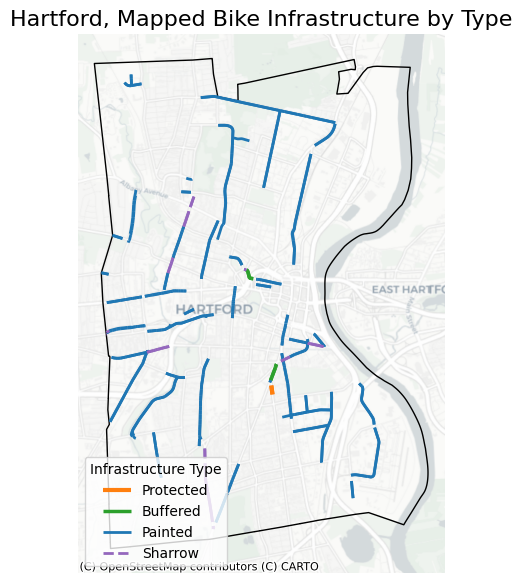

In [ ]:
# Subset bike infrastructure edges
bike_infra_edges = osm_edges[osm_edges["infra_type"] != "none"].copy()

# Set renderer if needed
set_renderer(renderer_map)

# Create figure and axis
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

# Define styles for each infra_type
infra_styles = {
    "protected": {"color": pdict["infra_protected"], "linestyle": "solid", "linewidth": 3, "label": "Protected"},
    "buffered":  {"color": pdict["infra_buffered"],  "linestyle": "solid", "linewidth": 2.5, "label": "Buffered"},
    "painted":   {"color": pdict["infra_painted"],   "linestyle": "solid", "linewidth": 2, "label": "Painted"},
    "sharrow":   {"color": pdict["infra_sharrow"],   "linestyle": "dashed","linewidth": 2, "label": "Sharrow"},
}

# Plot each infra type
for infra, style in infra_styles.items():
    subset = bike_infra_edges.query(f"infra_type == '{infra}'")
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=style["color"],
            linewidth=style["linewidth"],
            linestyle=style["linestyle"],
            label=style["label"]
        )

# Plot study area boundary
study_area_poly.plot(ax=ax,
                     edgecolor=pdict["osm_boundary"],
                     facecolor="none",
                     linewidth=pdict["line_base"])

# Add basemap
cx.add_basemap(ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

# Final touches
ax.set_axis_off()
ax.set_title(f"{area_name}, Mapped Bike Infrastructure by Type", fontsize=16)
ax.legend(title="Infrastructure Type", loc="lower left")

# Save the figure
save_fig(fig, os.path.join(results_fp, "bike_infra_edges_map"))


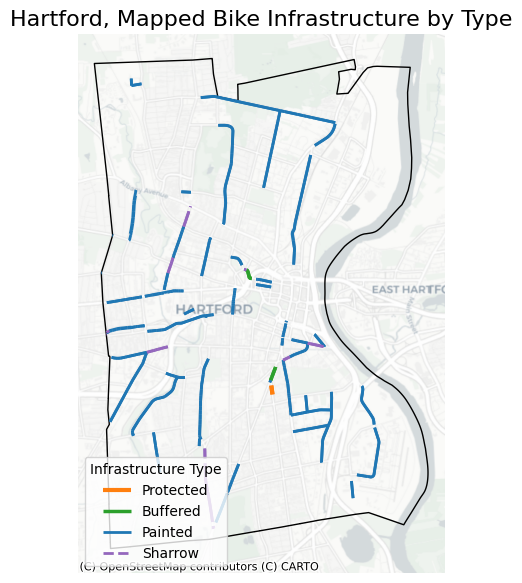

In [ ]:
# Subset bike infrastructure edges
drive_infra_edges = osm_edges[osm_edges["drive_infra_type"] != "none"].copy()

# Set renderer if needed
set_renderer(renderer_map)

# Create figure and axis
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

# Define styles for each infra_type
infra_styles = {
    "protected": {"color": pdict["infra_protected"], "linestyle": "solid", "linewidth": 3, "label": "Protected"},
    "buffered":  {"color": pdict["infra_buffered"],  "linestyle": "solid", "linewidth": 2.5, "label": "Buffered"},
    "painted":   {"color": pdict["infra_painted"],   "linestyle": "solid", "linewidth": 2, "label": "Painted"},
    "sharrow":   {"color": pdict["infra_sharrow"],   "linestyle": "dashed","linewidth": 2, "label": "Sharrow"},
}

# Plot each infra type
for infra, style in infra_styles.items():
    subset = drive_infra_edges.query(f"drive_infra_type == '{infra}'")
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=style["color"],
            linewidth=style["linewidth"],
            linestyle=style["linestyle"],
            label=style["label"]
        )

# Plot study area boundary
study_area_poly.plot(ax=ax,
                     edgecolor=pdict["osm_boundary"],
                     facecolor="none",
                     linewidth=pdict["line_base"])

# Add basemap
cx.add_basemap(ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

# Final touches
ax.set_axis_off()
ax.set_title(f"{area_name}, Mapped Bike Infrastructure by Type", fontsize=16)
ax.legend(title="Infrastructure Type", loc="lower left")

# Save the figure
save_fig(fig, os.path.join(results_fp, "bike_infra_edges_map"))


In [ ]:
# Rebuild graph using only bike infra edges and their nodes
bike_infra_edges = osm_edges[osm_edges["infra_type"] != "none"].copy()
bike_infra_edges = bike_infra_edges.reset_index()

# Filter nodes to only those used by bike infra
used_nodes = set(bike_infra_edges["u"]) | set(bike_infra_edges["v"])
bike_nodes = osm_nodes.loc[osm_nodes.index.intersection(used_nodes)].copy()

# Build graph without simplification
bike_graph = ox.graph_from_gdfs(bike_nodes, bike_infra_edges.set_index(["u", "v", "key"]))

# Count connected components
components = list(nx.connected_components(bike_graph.to_undirected()))
print(f"🔗 Connected Bike Infra Components: {len(components)}")


🔗 Connected Bike Infra Components: 40


## Maps and Stats

In [ ]:
print(f"🚦 {len(matches_df)} segment matches found")
print(f"✅ Hybrid matching complete for {study_area}. {len(osm_edges)} edges retained.")
matched_count = agg_matches["drive_orig_idx"].nunique()
total_drive_edges = len(edges_drive_filtered)
print(f"Matched {matched_count} of {total_drive_edges} drive edges ({matched_count / total_drive_edges:.1%})")

🚦 57576 segment matches found
✅ Hybrid matching complete for hartford_4. 4977 edges retained.
Matched 20989 of 20989 drive edges (100.0%)


In [ ]:
# 🎉 Done!
print("Final bounds check:")
print("Nodes bounds:", osm_nodes.total_bounds)
print("Edges bounds:", osm_edges.total_bounds)
print("CRS:", osm_edges.crs)

Final bounds check:
Nodes bounds: [307577.96016888 251316.60639023 313229.59359749 260583.72107642]
Edges bounds: [307577.96016888 251316.60639023 313229.59359749 260583.72107642]
CRS: EPSG:26956


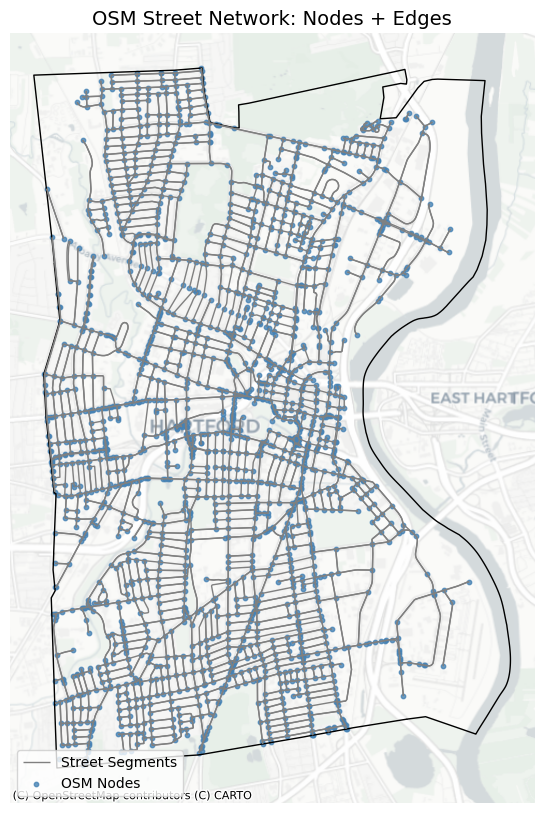

In [ ]:
# Visualize OSM Network: Nodes + Edges
fig, ax = plt.subplots(figsize=(10, 10))

# Plot edges and nodes
osm_edges.plot(ax=ax, color="gray", linewidth=1, label="Street Segments")
osm_nodes.plot(ax=ax, color="steelblue", markersize=10, alpha=0.8, label="OSM Nodes")

# Study area boundary
study_area_poly.plot(ax=ax, edgecolor="black", facecolor="none", linewidth=1)

# Add basemap
cx.add_basemap(ax, crs=osm_nodes.crs, source=pdict["basemap_primary"])

# Final touches
ax.set_title("OSM Street Network: Nodes + Edges", fontsize=14)
ax.set_axis_off()
ax.legend(loc="lower left")

# Save figure
save_fig(fig, os.path.join(results_fp, "osm_network"))


In [ ]:
# Summary of infrastructure types
print("Infrastructure type breakdown:")
print(osm_edges["infra_type"].value_counts())

Infrastructure type breakdown:
infra_type
none         4191
painted       696
sharrow        74
buffered       14
protected       2
Name: count, dtype: int64


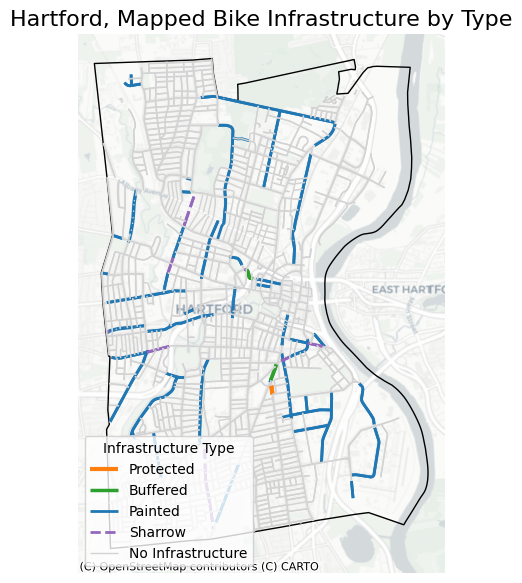

In [ ]:
set_renderer(renderer_map)
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

# Plot infrastructure types using pdict
infra_styles = {
    "protected": {"color": pdict["infra_protected"], "linestyle": "solid", "linewidth": 3, "label": "Protected"},
    "buffered":  {"color": pdict["infra_buffered"],  "linestyle": "solid", "linewidth": 2.5, "label": "Buffered"},
    "painted":   {"color": pdict["infra_painted"],   "linestyle": "solid", "linewidth": 2, "label": "Painted"},
    "sharrow":   {"color": pdict["infra_sharrow"],   "linestyle": "dashed","linewidth": 2, "label": "Sharrow"},
    "none":      {"color": pdict["infra_none"],      "linestyle": "solid", "linewidth": 1, "label": "No Infrastructure"},
}

for infra, style in infra_styles.items():
    subset = osm_edges.query(f"infra_type == '{infra}'")
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=style["color"],
            linewidth=style["linewidth"],
            linestyle=style["linestyle"],
            label=style["label"]
        )

# Boundary polygon
study_area_poly.plot(ax=ax,
                     edgecolor=pdict["osm_boundary"],
                     facecolor="none",
                     linewidth=pdict["line_base"])

# Basemap
cx.add_basemap(ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

# Final touches
ax.set_axis_off()
ax.set_title(f"{area_name}, Mapped Bike Infrastructure by Type", fontsize=16)
ax.legend(title="Infrastructure Type", loc="lower left")

# Save the plot
save_fig(fig, os.path.join(results_fp, "bike_infra_types"))

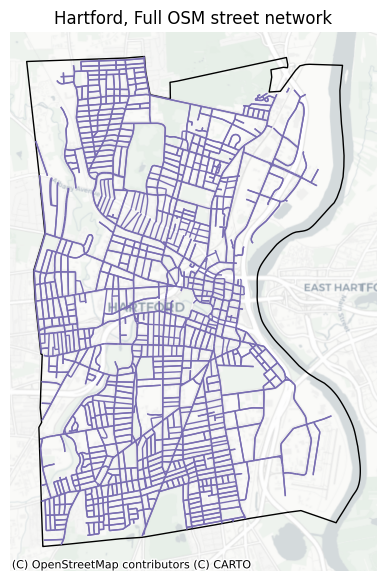

In [ ]:
# Visualize full OSM network
set_renderer(renderer_map)
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

# Plot full street network
osm_edges.plot(ax=ax, color=pdict["osm_base"], linewidth=pdict["line_base"])

# Plot the boundary polygon of the study area
study_area_poly.plot(ax=ax, edgecolor=pdict["base"], facecolor="None", linewidth=1)

# Add basemap from contextily
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=cx_tile_2)

# Final touches
ax.set_axis_off()
ax.set_title(f"{area_name}, Full OSM street network")

# Save figure
save_fig(fig, os.path.join(results_fp, "area_network_osm"))

# **Stress Assignment**

In [ ]:
# Clean and convert raw maxspeed and lanes columns
def clean_maxspeed(value):
    if pd.isna(value):
        return np.nan
    match = re.search(r"\d+", str(value))  # Extract first number
    return float(match.group()) if match else np.nan

osm_edges["maxspeed"] = osm_edges["maxspeed"].apply(clean_maxspeed)
osm_edges["lanes"] = pd.to_numeric(osm_edges["lanes"], errors="coerce")

# Estimate directional lanes based on road structure
def estimate_lanes_per_direction(row):
    lanes = row["lanes"]
    oneway = row["oneway"]
    if pd.isna(lanes):
        return np.nan
    lanes = int(round(lanes))
    if oneway:
        return lanes
    elif lanes == 1:
        return 1
    elif lanes % 2 == 0:
        return lanes // 2
    else:
        return (lanes - 1) // 2

osm_edges["lanes_per_direction"] = osm_edges.apply(estimate_lanes_per_direction, axis=1)

In [ ]:
# Count missing speed and lane values
total_edges = len(osm_edges)
missing_maxspeed = osm_edges["maxspeed"].isna().sum()
missing_lanes_per_direction = osm_edges["lanes_per_direction"].isna().sum()

print(f"Missing maxspeed values: {missing_maxspeed} ({missing_maxspeed / total_edges:.1%})")
print(f"Missing lanes_per_direction values: {missing_lanes_per_direction} ({missing_lanes_per_direction / total_edges:.1%})")

Missing maxspeed values: 4640 (93.2%)
Missing lanes_per_direction values: 4428 (89.0%)


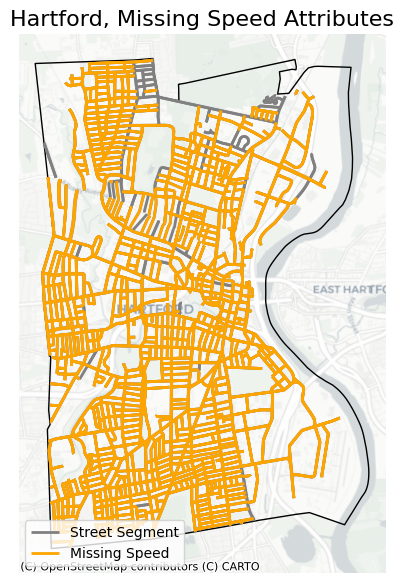

In [ ]:
set_renderer(renderer_map)
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

# Plot full street network
osm_edges.plot(
    ax=ax,
    color="gray",
    linewidth=2,
    label="Street Segment"
)

# Highlight missing speed
osm_edges[osm_edges["maxspeed"].isna()].plot(
    ax=ax,
    color="orange",
    linewidth=2,
    label="Missing Speed"
)

# Add study boundary and basemap
study_area_poly.plot(ax=ax, edgecolor="black", facecolor="none", linewidth=1)
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

# Final styling
ax.set_axis_off()
ax.set_title(f"{area_name}, Missing Speed Attributes", fontsize=16)
ax.legend(loc="lower left")

# Save figure without printing Legend object
save_fig(fig, os.path.join(results_fp, "missing_speed_map"))

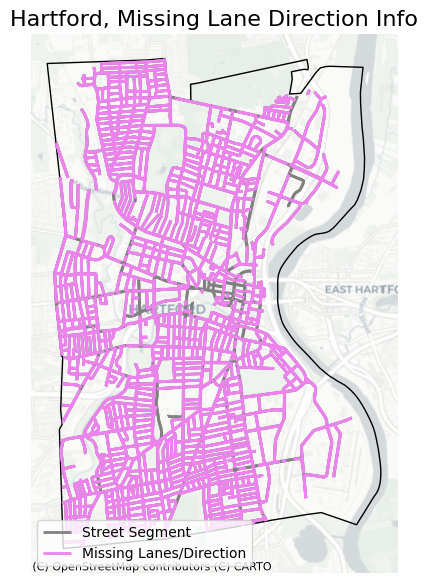

In [ ]:
set_renderer(renderer_map)
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

# Plot full network for context
osm_edges.plot(
    ax=ax,
    color="gray",
    linewidth=2,
    label="Street Segment"
)

# Highlight edges missing directional lane info
osm_edges[osm_edges["lanes_per_direction"].isna()].plot(
    ax=ax,
    color="violet",
    linewidth=2,
    label="Missing Lanes/Direction"
)

# Study area and basemap
study_area_poly.plot(ax=ax, edgecolor="black", facecolor="none", linewidth=1)
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

# Final styling
ax.set_axis_off()
ax.set_title(f"{area_name}, Missing Lane Direction Info", fontsize=16)
ax.legend(loc="lower left")

# Save figure to results folder
save_fig(fig, os.path.join(results_fp, "missing_lanes_direction_map"))

In [ ]:
def get_default_speed(row):
    hwy = str(row.get("highway", "")).lower()
    defaults = {
        "primary": 40,
        "secondary": 35,
        "tertiary": 30,
        "residential": 25,
        "unclassified": 25,
        "living_street": 25
    }
    return defaults.get(hwy, row["maxspeed"]) if pd.isna(row["maxspeed"]) else row["maxspeed"]

def get_default_lanes_per_direction(row):
    hwy = str(row.get("highway", "")).lower()
    defaults = {
        "primary": 2,
        "secondary": 2,
        "tertiary": 1,
        "residential": 1,
        "unclassified": 1,
        "living_street": 1
    }
    return defaults.get(hwy, row["lanes_per_direction"]) if pd.isna(row["lanes_per_direction"]) else row["lanes_per_direction"]

# Apply defaults
osm_edges["maxspeed"] = osm_edges.apply(get_default_speed, axis=1)
osm_edges["lanes_per_direction"] = osm_edges.apply(get_default_lanes_per_direction, axis=1)

In [ ]:
def bin_speed(speed):
    try:
        speed = float(speed)
        if 6 <= speed <= 10:
            return "6–10 mph"
        elif 11 <= speed <= 15:
            return "11–15 mph"
        elif 16 <= speed <= 20:
            return "16–20 mph"
        elif 21 <= speed <= 25:
            return "21–25 mph"
        elif 26 <= speed <= 30:
            return "26–30 mph"
        elif 31 <= speed <= 35:
            return "31–35 mph"
        elif speed > 35:
            return "36+ mph"
        else:
            return "Unknown"
    except:
        return "Unknown"

# Apply binning logic
osm_edges["speed_bin"] = osm_edges["maxspeed"].apply(bin_speed)


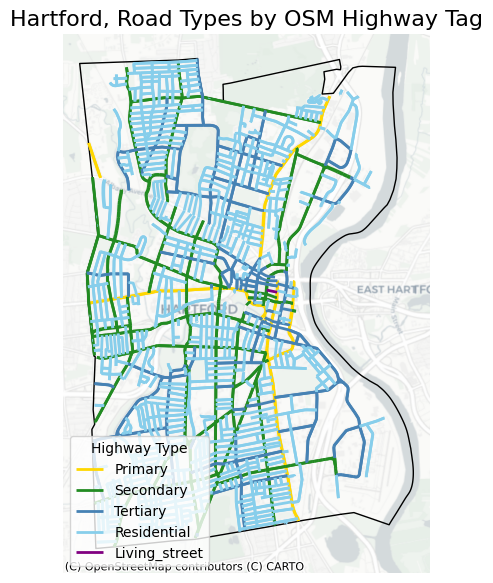

In [ ]:
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

for hwy_type, color in pdict["highway_colors"].items():
    subset = osm_edges.query(f"highway == '{hwy_type}'")
    if not subset.empty:
        subset.plot(ax=ax, color=color, linewidth=2, label=hwy_type.capitalize())

study_area_poly.plot(ax=ax, edgecolor=pdict["base"], facecolor="none", linewidth=1)
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title(f"{area_name}, Road Types by OSM Highway Tag", fontsize=16)
ax.legend(title="Highway Type", loc="lower left")
save_fig(fig, os.path.join(results_fp, "highway_type_map"))

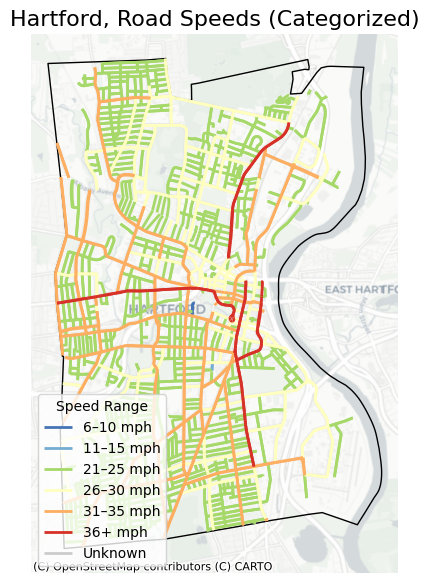

In [ ]:
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

for bin_val, color in pdict["speed_palette"].items():
    subset = osm_edges.query(f"speed_bin == '{bin_val}'")
    if not subset.empty:
        subset.plot(ax=ax, color=color, linewidth=2, label=bin_val)

study_area_poly.plot(ax=ax, edgecolor=pdict["base"], facecolor="none", linewidth=1)
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title(f"{area_name}, Road Speeds (Categorized)", fontsize=16)
ax.legend(title="Speed Range", loc="lower left")
save_fig(fig, os.path.join(results_fp, "speed_bins"))

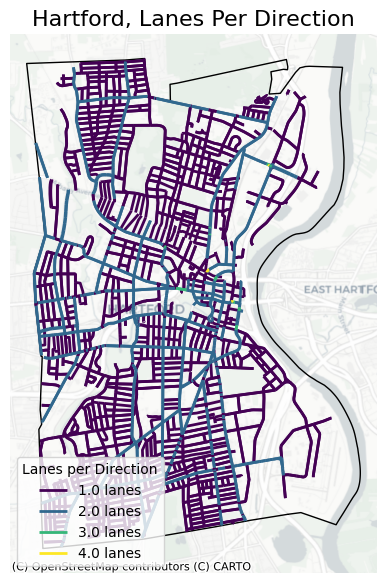

In [ ]:
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

# Create a color map from unique lane values
lane_vals = osm_edges["lanes_per_direction"].dropna().unique()
lane_vals_sorted = sorted(lane_vals)
lane_cmap = plt.get_cmap("viridis", len(lane_vals_sorted))
lane_colors = {val: lane_cmap(i) for i, val in enumerate(lane_vals_sorted)}

# Plot each lane count category
for val, color in lane_colors.items():
    subset = osm_edges.query(f"lanes_per_direction == {val}")
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=color,
            linewidth=2,
            label=f"{val} lanes"
        )

study_area_poly.plot(ax=ax, edgecolor="black", facecolor="none", linewidth=1)
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title(f"{area_name}, Lanes Per Direction", fontsize=16)
ax.legend(title="Lanes per Direction", loc="lower left")

# Save figure
save_fig(fig, os.path.join(results_fp, "lanes_per_direction_map"))

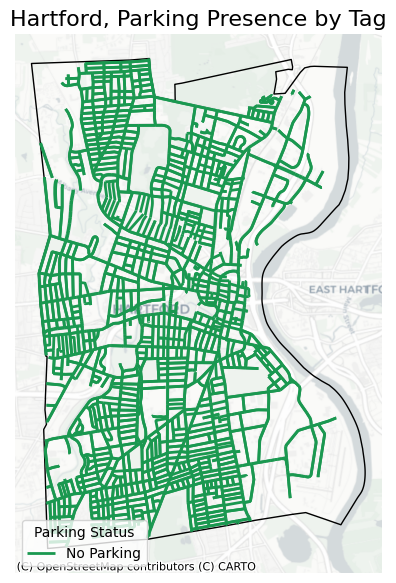

In [ ]:
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

for has_parking, color in pdict["parking_colors"].items():
    subset = osm_edges.query(f"parking == {has_parking}")
    label = "Parking" if has_parking else "No Parking"
    if not subset.empty:
        subset.plot(ax=ax, color=color, linewidth=2, label=label)

study_area_poly.plot(ax=ax, edgecolor=pdict["base"], facecolor="none", linewidth=1)
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title(f"{area_name}, Parking Presence by Tag", fontsize=16)
ax.legend(title="Parking Status", loc="lower left")
save_fig(fig, os.path.join(results_fp, "parking_presence_map"))

In [ ]:
def assign_stress(attrs):
    infra = attrs["infra_type"]
    lanes = attrs["lanes_per_direction"]
    speed = attrs["maxspeed"]
    parking = attrs["parking"]
    highway = attrs["highway"]

    if infra == "protected" or highway == "living_street":
        return "low"

    elif lanes == 2:
        if infra == "painted" and speed <= 20:
            return "low"
        elif infra == "buffered" and not parking and speed <= 30:
            return "low"
        else:
            return "high"

    elif lanes == 1:
        if speed <= 20:
            return "low"
        elif speed <= 25 and highway == "residential":
            return "low"
        elif infra == "painted":
            if speed <= 25:
                return "low"
            elif speed <= 30 and not parking:
                return "low"
            else:
                return "high"
        elif infra == "buffered":
            if speed <= 30:
                return "low"
            elif speed <= 35 and not parking:
                return "low"
            else:
                return "high"
        else:
            return "high"

    else:
        return "high"

In [ ]:
osm_edges["stress_init"] = osm_edges.apply(assign_stress, axis=1)

# Flag mismatched segments
osm_edges["bike_infra_flag"] = (
    (osm_edges["infra_type"] != "none") &
    (osm_edges["stress_init"] == "high")
)

print("Edges with bike infra + high stress:",
      osm_edges["bike_infra_flag"].sum())

Edges with bike infra + high stress: 547


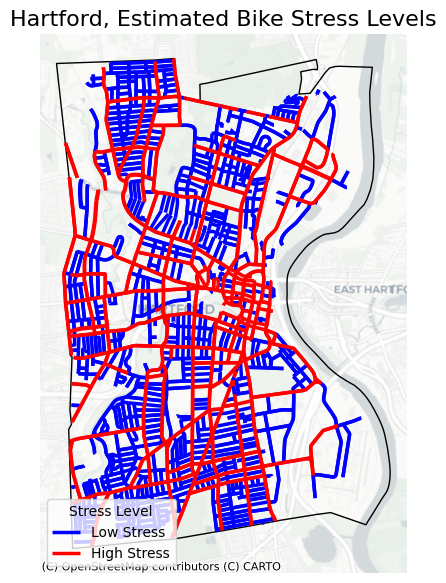

In [ ]:
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

for stress_level, style in pdict["stress_styles"].items():
    subset = osm_edges.query(f"stress_init == '{stress_level}'")
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=style["color"],
            linewidth=style["linewidth"],
            linestyle=style["linestyle"],
            label=style["label"]
        )

study_area_poly.plot(ax=ax, edgecolor=pdict["base"], facecolor="none", linewidth=1)
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title(f"{area_name}, Estimated Bike Stress Levels", fontsize=16)
ax.legend(title="Stress Level", loc="lower left")
save_fig(fig, os.path.join(results_fp, "bike_stress_levels"))

# **Intrastructure Recommendation**

In [ ]:
infra_levels = ["none", "sharrow", "painted", "buffered", "protected"]

def compute_ideal_infra(attrs):
    orig = attrs.get("infra_type", "none")
    stress = attrs.get("stress_init", "high")
    highway = attrs.get("highway", "unknown")

    # Already low stress and no infra → allow sharrow
    if highway == "living_street" and orig == "none":
        return "none"

    if stress == "low" and orig in ("none", "sharrow"):
        return "sharrow"

    if stress == "low":
        return orig

    # Simulate upgrades
    try:
        cur_idx = infra_levels.index(orig)
    except ValueError:
        cur_idx = 0

    for infra in infra_levels[cur_idx + 1:]:
        attrs_sim = attrs.copy()
        attrs_sim["infra_type"] = infra
        if assign_stress(attrs_sim) == "low":
            return infra

    # Fallback: protected always works
    return "protected"

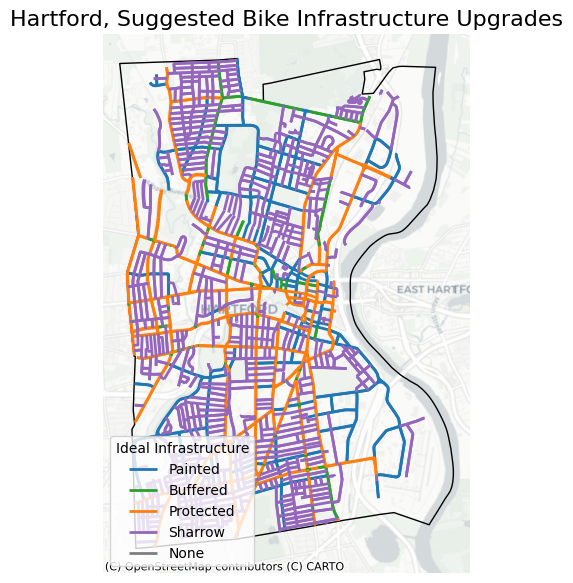

In [ ]:
# Compute recommended infrastructure level
osm_edges["ideal_infra"] = osm_edges.apply(compute_ideal_infra, axis=1)

fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

for infra_type, color in pdict["infra_colors"].items():
    subset = osm_edges.query(f"ideal_infra == '{infra_type}'")
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=color,
            linewidth=2,
            label=infra_type.capitalize()
        )

study_area_poly.plot(ax=ax, edgecolor=pdict["base"], facecolor="none", linewidth=1)
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title(f"{area_name}, Suggested Bike Infrastructure Upgrades", fontsize=16)
ax.legend(title="Ideal Infrastructure", loc="lower left")
save_fig(fig, os.path.join(results_fp, "ideal_infra_map"))

In [ ]:
# Add segment length in meters
osm_edges["length"] = osm_edges.geometry.length

# Group and summarize by infrastructure level
summary_table = (
    osm_edges
    .groupby("ideal_infra")["length"]
    .sum()
    .reset_index()
    .rename(columns={"length": "total_length_m"})
)

# Add percentage breakdown
total_network_length = summary_table["total_length_m"].sum()
summary_table["percent"] = (summary_table["total_length_m"] / total_network_length * 100).round(2)

# Sort by longest total first
summary_table = summary_table.sort_values("total_length_m", ascending=False)

print(summary_table)

  ideal_infra  total_length_m  percent
4     sharrow   365696.074657    55.73
3   protected   142088.965778    21.65
2     painted   121620.035398    18.54
0    buffered    26549.335686     4.05
1        none      200.107625     0.03


# **Growth Logic**

In [ ]:
infra_levels = ["sharrow", "painted", "buffered", "protected"]
max_tier = "protected"  # conservative default — disables building logic if needed
tier_index = infra_levels.index(max_tier)

In [ ]:
osm_edges["can_build"] = osm_edges["ideal_infra"].apply(
    lambda val: infra_levels.index(val) <= tier_index if val in infra_levels else False
)

update_mask = (
    (osm_edges["infra_type"].isin(["painted", "buffered", "protected", "sharrow"])) &
    (osm_edges["stress_init"] == "high") &
    (osm_edges["can_build"])
)
osm_edges["update_existing"] = update_mask
osm_edges["build_action"] = osm_edges["can_build"] | osm_edges["update_existing"]

In [ ]:
ox.settings.overpass_url = "https://overpass-api.de/api/interpreter"

In [ ]:
# Step 1: Define tags for landuse features
landuse_tags = {
    "landuse": [
        "residential", "commercial", "retail", "industrial",
        "education", "mixed", "government"
    ]
}

# Step 2: Validate and prepare study area geometry for Overpass query
study_geom_raw = study_area_poly.unary_union
study_geom_fixed = study_geom_raw.buffer(0)  # repair if invalid
study_geom_wgs = gpd.GeoSeries([study_geom_fixed], crs=study_area_poly.crs).to_crs("EPSG:4326").iloc[0]

# Step 3: Load landuse features from OSM
landuse_raw = ox.features_from_polygon(study_geom_wgs, tags=landuse_tags)

# Step 4: Clean and prepare the data
landuse_zones = (
    landuse_raw.reset_index()
    .dropna(subset=["geometry", "landuse"])
    .loc[:, ["geometry", "landuse"]]
    .copy()
)


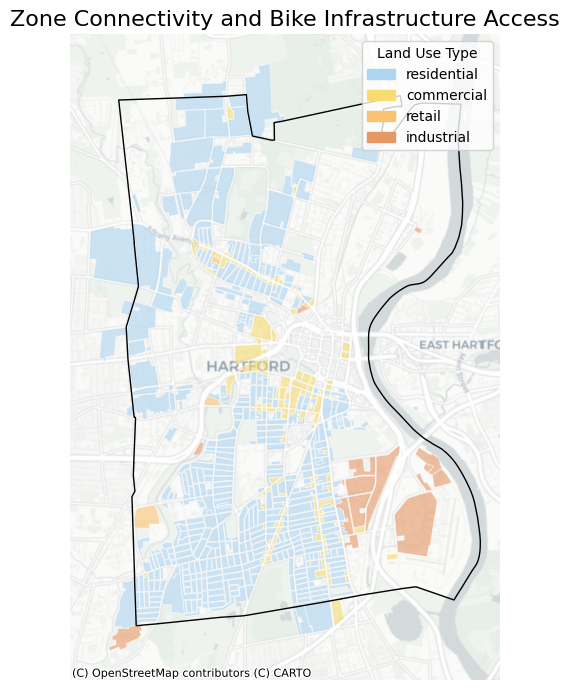

In [ ]:
# Optional: landuse color scheme
landuse_colors = {
    "residential": "#AED6F1",
    "commercial": "#F7DC6F",
    "retail": "#F8C471",
    "industrial": "#E59866",
    "education": "#82E0AA",
    "mixed": "#C39BD3",
    "government": "#F1948A"
}

# Restore original geometry for visualization
landuse_zones = landuse_zones.set_geometry("geometry")
landuse_zones = landuse_zones.to_crs(study_area_poly.crs)

fig, ax = plt.subplots(figsize=(8, 7))

# Filter to include only present land uses
present_landuses = landuse_zones["landuse"].unique()
filtered_colors = {k: v for k, v in landuse_colors.items() if k in present_landuses}

# Plot each zone with its color
for landuse, color in filtered_colors.items():
    subset = landuse_zones.query(f"landuse == '{landuse}'")
    if not subset.empty:
        subset.plot(
            ax=ax,
            facecolor=color,
            edgecolor="white",
            linewidth=0.5,
            alpha=0.6
        )

# Build legend only for present land uses
legend_patches = [
    mpatches.Patch(color=color, label=landuse)
    for landuse, color in filtered_colors.items()
]
ax.legend(handles=legend_patches, loc="upper right", title="Land Use Type", frameon=True)

study_area_poly.plot(ax=ax, edgecolor=pdict["base"], facecolor="none", linewidth=1)
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

# Final styling
ax.set_axis_off()
ax.set_title("Zone Connectivity and Bike Infrastructure Access", fontsize=16)
plt.tight_layout()

# Save the figure
save_fig(fig, os.path.join(results_fp, "landuse_zone_map"))

In [ ]:
residential_zones = landuse_zones[landuse_zones['landuse'] == 'residential'].copy()

# Step 5: Compute centroid for each polygon
landuse_zones["centroid"] = landuse_zones.geometry.centroid
landuse_zones = landuse_zones.set_geometry("centroid")
landuse_zones = landuse_zones.to_crs(study_area_poly.crs)  # match your main CRS

# Step 6: Review what came back
print(landuse_zones["landuse"].value_counts())

landuse
residential    491
commercial     139
industrial      19
retail           4
Name: count, dtype: int64


In [ ]:
# Define zone-to-zone pair priority scores
zone_pair_scores = {
    ("residential", "commercial"): 3,
    ("residential", "retail"): 3,
    ("residential", "education"): 2,
    ("residential", "mixed"): 2,
    ("residential", "government"): 2,
    ("residential", "industrial"): 0,

    ("education", "commercial"): 2,
    ("education", "government"): 1,
    ("commercial", "mixed"): 2,
    # ... expand as needed
}

# Helper to assign a score
def get_zone_score(from_zone, to_zone):
    return zone_pair_scores.get((from_zone, to_zone), zone_pair_scores.get((to_zone, from_zone), 1))


In [ ]:
if "stress_final" not in osm_edges.columns:
    osm_edges["stress_final"] = osm_edges["stress_init"]

# Step 1: Define minimum proximity to existing bike infra (meters)
infra_search_radius = 500

# Step 2: Create spatial index of low-stress infrastructure nodes
low_stress_edges = osm_edges.query("infra_type != 'none' and stress_final == 'low'")
low_stress_nodes = pd.Series(list(low_stress_edges.index.get_level_values(0)) + list(low_stress_edges.index.get_level_values(1)))
low_stress_coords = osm_nodes.loc[low_stress_nodes.unique(), ["x", "y"]]

# Step 3: Tag zone centroids as connected if within proximity
def is_near_infra(point):
    distances = np.linalg.norm(low_stress_coords.values - np.array([point.x, point.y]), axis=1)
    return (distances < infra_search_radius).any()

landuse_zones["connected_to_bike_infra"] = landuse_zones["centroid"].apply(is_near_infra)


In [ ]:
# Create pairings between zone centroids
zone_pairs = []
for a, b in itertools.combinations(landuse_zones.index, 2):
    from_zone = landuse_zones.loc[a, "landuse"]
    to_zone = landuse_zones.loc[b, "landuse"]
    score = get_zone_score(from_zone, to_zone)

    if score > 0:
        zone_pairs.append({
            "from_id": a,
            "to_id": b,
            "score": score,
            "from_geom": landuse_zones.loc[a, "centroid"],
            "to_geom": landuse_zones.loc[b, "centroid"]
        })

zone_pair_df = pd.DataFrame(zone_pairs)
zone_pair_df = zone_pair_df.sort_values(by="score", ascending=False)


In [ ]:
SNAP_RADIUS = 500  # meters

def snap_point_to_infra_or_zone(point, low_stress_coords, zone_centroids, radius=SNAP_RADIUS):
    # Step 1: Try snapping to nearby bike infra node
    distances = np.linalg.norm(low_stress_coords.values - np.array([point.x, point.y]), axis=1)
    if (distances < radius).any():
        nearest_idx = np.argmin(distances)
        snapped_coords = low_stress_coords.iloc[nearest_idx]
        return Point(snapped_coords["x"], snapped_coords["y"]), "infra"

    # Step 2: Otherwise, check for nearby zone centroid
    zone_dists = zone_centroids.distance(point)
    min_dist = zone_dists.min()
    if min_dist < radius:
        nearest_zone = zone_centroids.loc[zone_dists.idxmin()]
        return nearest_zone.geometry, "zone"

    # Step 3: No snap within radius
    return point, "none"

In [ ]:
# Step 1: Define grid spacing in meters
grid_spacing = 1707  # meters

# Step 2: Project study area to metric CRS
study_proj = study_area_poly.to_crs(study_crs)

# Step 3: Get bounding box
minx, miny, maxx, maxy = study_proj.total_bounds

# Step 4: Generate grid coordinates
x_coords = np.arange(minx, maxx, grid_spacing)
y_coords = np.arange(miny, maxy, grid_spacing)
grid_points = [shapely.geometry.Point(x, y) for x in x_coords for y in y_coords]

# Step 5: Create GeoDataFrame and clip to study area
grid_gdf = gpd.GeoDataFrame(geometry=grid_points, crs=study_crs)
grid_gdf = gpd.clip(grid_gdf, study_proj)

# Step 6: Reproject grid to match rest of notebook
grid_gdf = grid_gdf.to_crs(study_area_poly.crs)

print(f"Generated {len(grid_gdf)} grid points spaced ~{grid_spacing} meters apart.")


Generated 14 grid points spaced ~1707 meters apart.


In [ ]:
# Extract zone centroid geometry series
zone_centroids = landuse_zones.set_geometry("centroid").to_crs(study_area_poly.crs)

snap_results = grid_gdf["geometry"].apply(
    lambda pt: snap_point_to_infra_or_zone(pt, low_stress_coords, zone_centroids)
)

grid_gdf = grid_gdf.assign(
    snapped_point=[result[0] for result in snap_results],
    snap_source=[result[1] for result in snap_results]
)

grid_gdf["snapped_point"] = grid_gdf["snapped_point"].apply(
    lambda geom: geom.centroid if geom.geom_type != "Point" else geom
)

In [ ]:
# Toggle to upgrade high-stress bike infra segments for connectivity
upgrade_existing_infra = True  # ← Set to False to disable

if upgrade_existing_infra:
    # Identify high-stress bike infra that could be stitched
    upgrade_mask = (
        (osm_edges["infra_type"] != "none") &
        (osm_edges["stress_final"] == "high")
    )

    osm_edges.loc[upgrade_mask, "stress_final"] = "low"
    osm_edges.loc[upgrade_mask, "growth_priority"] = "simulated_upgrade"

init_low_stress = osm_edges[osm_edges['stress_init'] == 'low']

# Refresh graph with modified edge data
if "osmid" in osm_nodes.columns:
    osm_nodes = osm_nodes.set_index("osmid")

# Ensure edges are indexed correctly for MultiGraph support
if not isinstance(osm_edges.index, pd.MultiIndex):
    if all(col in osm_edges.columns for col in ["u", "v", "key"]):
        osm_edges = osm_edges.set_index(["u", "v", "key"])

G = ox.graph_from_gdfs(osm_nodes, osm_edges)

# Rebuild low-stress edge and node index after upgrade toggle
low_stress_edges = osm_edges.query("infra_type != 'none' and stress_final == 'low'")
low_stress_nodes = pd.Series(list(low_stress_edges.index.get_level_values(0)) + list(low_stress_edges.index.get_level_values(1)))
low_stress_coords = osm_nodes.loc[low_stress_nodes.unique(), ["x", "y"]]

In [ ]:
# Build bike-only low-stress subgraph
infra_edges = osm_edges.query("infra_type != 'none' and stress_final == 'low'")
G_bike = ox.graph_from_gdfs(osm_nodes, infra_edges)

# Detect disconnected components
components = list(nx.weakly_connected_components(G_bike))
print(f"Found {len(components)} disconnected low-stress bike clusters.")

# Find endpoints of each component
def find_endpoints(subgraph):
    return [n for n in subgraph if G_bike.degree(n) == 1]

component_endpoints = [find_endpoints(comp) for comp in components]

# Route between endpoints to identify bridging paths
bridge_pairs = []
for i, comp_a in enumerate(component_endpoints):
    for j, comp_b in enumerate(component_endpoints):
        if i >= j:
            continue
        for u in comp_a:
            for v in comp_b:
                try:
                    length = nx.shortest_path_length(G, source=u, target=v, weight="length")
                    bridge_pairs.append((u, v, length))
                except:
                    continue

# Build bridge MST and extract segments
G_bridges = nx.Graph()
G_bridges.add_weighted_edges_from(bridge_pairs)
bridge_mst = nx.minimum_spanning_tree(G_bridges)
bridge_paths = []

for u, v in bridge_mst.edges:
    try:
        path = nx.shortest_path(G, source=u, target=v, weight="length")
        bridge_paths.extend([(path[i], path[i + 1]) for i in range(len(path) - 1)])
    except:
        continue

# Save bridging segments separately
bridge_edge_tuples = bridge_paths.copy()

Found 1509 disconnected low-stress bike clusters.


In [ ]:
# Reconstruct OSMnx street graph from osm_nodes and osm_edges
G = ox.graph_from_gdfs(osm_nodes, osm_edges)

# Step 1: Snap each snapped point to a network node
grid_gdf["nearest_node"] = grid_gdf["snapped_point"].apply(
    lambda pt: ox.distance.nearest_nodes(G, X=pt.x, Y=pt.y)
)

# Step 2: Collect grid seed nodes
grid_seed_nodes = set(grid_gdf["nearest_node"].unique())

# Step 3: Collect endpoints of simulated upgrades
upgrade_edges = osm_edges.query("growth_priority == 'simulated_upgrade'")
upgrade_nodes = set(
    list(upgrade_edges.index.get_level_values(0)) +
    list(upgrade_edges.index.get_level_values(1))
)

# Nodes from original low-stress infrastructure
low_stress_nodes = set(
    low_stress_edges.index.get_level_values(0).tolist() +
    low_stress_edges.index.get_level_values(1).tolist()
)

# Step 4: Combine into final seed node set
seed_nodes = list(grid_seed_nodes | upgrade_nodes | low_stress_nodes)
print(f"Expanded MST seed node set to {len(seed_nodes)} including upgraded infra endpoints.")

Expanded MST seed node set to 462 including upgraded infra endpoints.


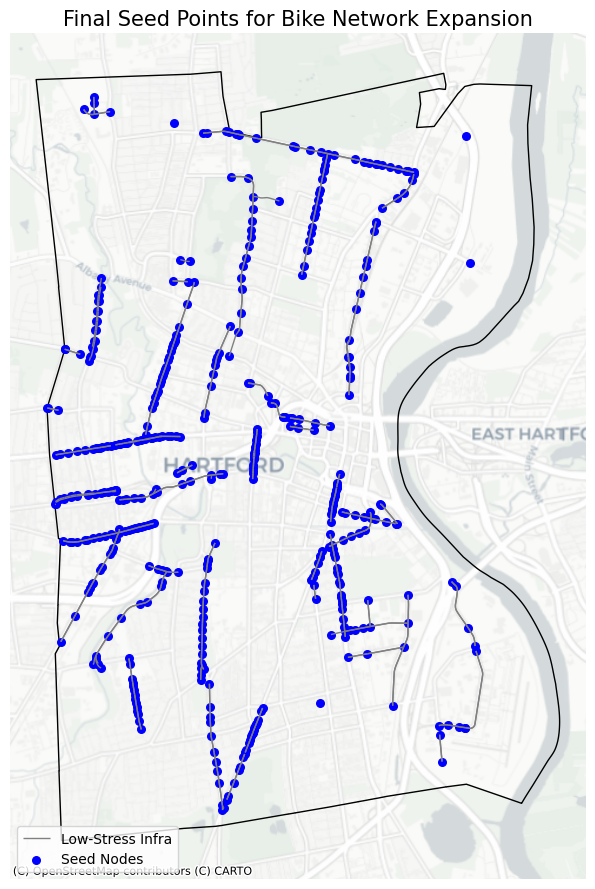

In [ ]:
# Step 1: Extract seed node coordinates from osm_nodes
seed_node_coords = osm_nodes.loc[seed_nodes, ["x", "y"]]

# Step 2: Create a GeoDataFrame
seed_gdf = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(seed_node_coords["x"], seed_node_coords["y"]),
    crs=osm_nodes.crs
)

# Step 3: Plot seed points over base map
fig, ax = plt.subplots(figsize=(13, 9))

# Plot study area
study_area_poly.plot(ax=ax, edgecolor="black", facecolor="none")

# Plot existing low-stress infrastructure for context
osm_edges.query("infra_type != 'none' and stress_final == 'low'").plot(
    ax=ax, color="gray", linewidth=1, label="Low-Stress Infra"
)

# Plot seed nodes
seed_gdf.plot(ax=ax, color="blue", markersize=30, label="Seed Nodes")

# Basemap and styling
cx.add_basemap(ax, crs=osm_nodes.crs, source=cx.providers.CartoDB.Positron)
ax.set_title("Final Seed Points for Bike Network Expansion", fontsize=15)
ax.set_axis_off()
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()


In [ ]:
use_landuse_weights = True  # ← Switch to False to ignore zone priority scores

node_landuse_map = {}

# Map centroid zone types to snapped nodes
for idx, row in grid_gdf.iterrows():
    node = row["nearest_node"]
    if row["snap_source"] == "zone":
        snapped_geom = row["snapped_point"]
        matching_zone = landuse_zones[landuse_zones["centroid"].distance(snapped_geom) < 10]  # tolerance threshold
        if not matching_zone.empty:
            node_landuse_map[node] = matching_zone.iloc[0]["landuse"]

# Step 5: Prepare node pairs for MST using landuse-weighted logic (if toggled)
pair_data = []
for u, v in combinations(seed_nodes, 2):
    try:
        length = nx.shortest_path_length(G, source=u, target=v, weight="length")

        zone_u = node_landuse_map.get(u)
        zone_v = node_landuse_map.get(v)
        score = get_zone_score(zone_u, zone_v) if zone_u and zone_v else 1

        if use_landuse_weights:
            weight = length / score if score > 0 else length
        else:
            weight = length

        pair_data.append((u, v, weight))
    except:
        continue

In [ ]:
# Step 6: Build weighted graph and extract MST
G_pair = nx.Graph()
G_pair.add_weighted_edges_from(pair_data)
mst_edges = list(nx.minimum_spanning_tree(G_pair).edges)

# Step 7: Extract full network paths for each MST edge
grid_edge_tuples = []
skipped_pairs = 0

for u, v in mst_edges:
    try:
        path = nx.shortest_path(G, source=u, target=v, weight="length")
        edge_segments = [(path[i], path[i + 1]) for i in range(len(path) - 1)]
        grid_edge_tuples.extend(edge_segments)
    except:
        skipped_pairs += 1
print(f"Skipped {skipped_pairs} MST edge(s) due to disconnected routing.")

# Step 8: Merge with connectivity bridges
growth_edge_tuples = bridge_edge_tuples + grid_edge_tuples

# Step 9: Build a GeoDataFrame of candidate growth edges
growth_edge_df = pd.DataFrame(growth_edge_tuples, columns=["u", "v"])
growth_edge_df["key"] = 0  # default key for MultiIndex

candidate_edges = growth_edge_df.merge(
    osm_edges.reset_index(),
    on=["u", "v"],
    how="left"
).dropna(subset=["geometry"])

candidate_gdf = gpd.GeoDataFrame(candidate_edges, geometry="geometry", crs=osm_edges.crs)

print(f"Routed {len(candidate_gdf)} candidate segments from MST and upgrade stitching.")

Skipped 0 MST edge(s) due to disconnected routing.
Routed 874 candidate segments from MST and upgrade stitching.


In [ ]:
# Step 1: Prepare candidate edge MultiIndex
candidate_edges_clean = candidate_gdf.copy()
candidate_edges_clean["key"] = candidate_edges_clean.get("key", 0)  # default key if missing
candidate_edges_clean[["u", "v", "key"]] = candidate_edges_clean[["u", "v", "key"]].astype(int)
candidate_edges_clean.set_index(["u", "v", "key"], inplace=True)

# Step 2: Ensure osm_edges has a proper MultiIndex
if not isinstance(osm_edges.index, pd.MultiIndex) or not set(["u", "v", "key"]).issubset(osm_edges.index.names):
    if "key" not in osm_edges.columns:
        osm_edges["key"] = 0
    osm_edges = osm_edges.reset_index().set_index(["u", "v", "key"])

# Step 3: Filter buildable segments
buildable_segments = osm_edges.query("build_action == True").copy()

# Identify existing low-stress infrastructure segments
existing_low_stress_idx = osm_edges.query(
    "infra_type != 'none' and stress_final == 'low'"
).index

# Remove overlapping segments from candidate set
filtered_candidates = candidate_edges_clean[
    ~candidate_edges_clean.index.isin(existing_low_stress_idx)
].copy()

# Step 4: Include simulated upgrade segments in candidate set
simulated_upgrade_idx = osm_edges.query("growth_priority == 'simulated_upgrade'").index
upgrade_segments = osm_edges.loc[simulated_upgrade_idx].copy()

# Assign expected fields (no need to touch the index again)
upgrade_segments["ideal_infra"] = upgrade_segments["infra_type"]  # Simulated type
upgrade_segments["growth_priority"] = "simulated_upgrade"

# Merge with candidate edges from MST routing
growth_candidates = pd.concat([
    filtered_candidates.loc[
        filtered_candidates.index.intersection(buildable_segments.index)
    ].assign(growth_priority="MST_corridor"),
    upgrade_segments
])

print(f"Tagged {len(growth_candidates)} segments from candidate corridors as buildable expansions.")

Tagged 862 segments from candidate corridors as buildable expansions.


In [ ]:
# Add buildable links to original graph with duplication safeguard
for idx, row in growth_candidates.iterrows():
    u, v, k = idx
    geom = row.geometry

    # Skip if edge already exists with same key
    if G.has_edge(u, v, k):
        continue

    attrs = {
        "length": geom.length,
        "growth_priority": row.get("growth_priority", "MST_corridor"),
        "simulated_infra": row["ideal_infra"],
        "simulated_stress": "low",
        "added_by_model": True
    }

    G.add_edge(u, v, k, **attrs)

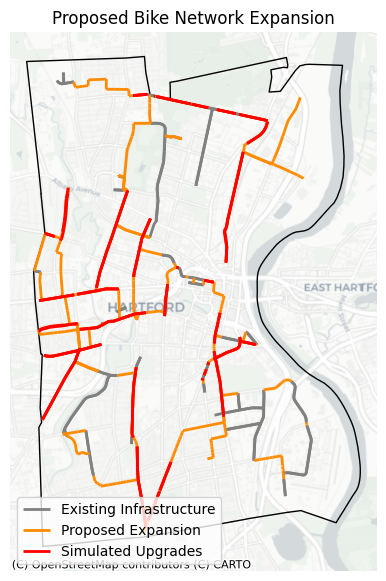

In [ ]:
upgrade_segments = osm_edges.query("growth_priority == 'simulated_upgrade'").copy()

fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

# Original infrastructure
osm_edges.query(
    "infra_type != 'none' and stress_final == 'low' and growth_priority != 'simulated_upgrade'"
).plot(
    ax=ax, color="gray", linewidth=2, label="Existing Infrastructure"
)

# Proposed growth links
growth_candidates.plot(
    ax=ax, color="darkorange", linewidth=2, label="Proposed Expansion"
)

# Simulated upgrades (existing infra that needs upgrade)
if not upgrade_segments.empty:
    upgrade_segments.plot(
        ax=ax,
        color="red",
        linewidth=2,
        label="Simulated Upgrades"
    )

study_area_poly.plot(ax=ax, edgecolor="black", facecolor="none")
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title("Proposed Bike Network Expansion")
ax.legend(loc="lower left")
save_fig(fig, os.path.join(results_fp, "bike_network_growth"))


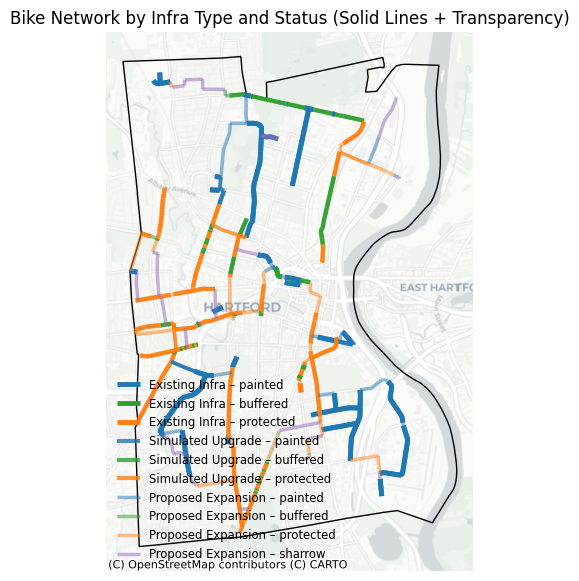

In [ ]:
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

def plot_with_alpha_and_width(df, label_prefix, alpha, linewidth):
    for infra_type, color in pdict["infra_colors"].items():
        subset = df.query(f"ideal_infra == '{infra_type}'")
        if not subset.empty:
            subset.plot(
                ax=ax,
                color=color,
                linewidth=linewidth,
                linestyle="solid",
                alpha=alpha,
                label=f"{label_prefix} – {infra_type}"
            )

# Existing infra (bold line)
plot_with_alpha_and_width(
    osm_edges.query("infra_type != 'none' and stress_final == 'low' and growth_priority != 'simulated_upgrade'"),
    "Existing Infra", alpha=1.0, linewidth=3.5
)

# Simulated upgrades (medium line)
plot_with_alpha_and_width(
    osm_edges.query("growth_priority == 'simulated_upgrade'"),
    "Simulated Upgrade", alpha=0.8, linewidth=3
)

# Proposed expansion (lighter line)
plot_with_alpha_and_width(
    growth_candidates.query("growth_priority == 'MST_corridor'"),
    "Proposed Expansion", alpha=0.5, linewidth=2.5
)

# Background map and layout
study_area_poly.plot(ax=ax, edgecolor="black", facecolor="none")
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title("Bike Network by Infra Type and Status (Solid Lines + Transparency)")
ax.legend(loc="lower left", fontsize="small", frameon=False)
save_fig(fig, os.path.join(results_fp, "bike_network_infra_type"))

# **Summary**

In [ ]:
# 1. All existing bike infrastructure
existing_all = osm_edges[osm_edges["infra_type"] != "none"].copy()
stats_existing_all = get_bike_stats(existing_all, label="Existing (All)")

# 2. Low-stress subset of existing infrastructure
existing_low_stress = osm_edges.query(
    "infra_type != 'none' and stress_init == 'low'"
).copy()
stats_existing_low = get_bike_stats(existing_low_stress, label="Existing (Low-Stress)")

# 3. Proposed network (low-stress, non-simulated upgrades + growth + optional upgrades)
proposed_existing = osm_edges.query(
    "infra_type != 'none' and stress_final == 'low' and growth_priority != 'simulated_upgrade'"
).copy()

proposed_edges = proposed_existing.copy()

# Add growth candidates if available
if "growth_candidates" in locals() and not growth_candidates.empty:
    proposed_edges = pd.concat([proposed_edges, growth_candidates])

# Add upgrade segments if available
if "upgrade_segments" in locals() and not upgrade_segments.empty:
    proposed_edges = pd.concat([proposed_edges, upgrade_segments])

# Optional: Remove duplicate geometries
proposed_edges = proposed_edges.drop_duplicates(subset=["geometry"])

# Compute stats for proposed
stats_proposed = get_bike_stats(proposed_edges, label="Proposed Network")

# Combine all stats
stats_df = pd.DataFrame([
    stats_existing_low,
    stats_existing_all,
    stats_proposed
])

# Display the comparison table
from tabulate import tabulate

print("\n🚲 Bike Infrastructure Network Comparison 🚲")
print(tabulate(stats_df, headers="keys", tablefmt="fancy_grid", showindex=False))



🚲 Bike Infrastructure Network Comparison 🚲
╒═══════════════════════╤═══════════════════════════╤═══════════════════════╤════════════════════════╤══════════════════════════╤══════════════════════╤═════════════════════╕
│ Network               │   Total Infra Length (km) │   Coverage Area (km²) │   Connected Components │   Largest Component (km) │   Largest % of Drive │   Largest % of Bike │
╞═══════════════════════╪═══════════════════════════╪═══════════════════════╪════════════════════════╪══════════════════════════╪══════════════════════╪═════════════════════╡
│ Existing (Low-Stress) │                     33.4  │                  9.42 │                     30 │                     3.33 │                 0.51 │                9.96 │
├───────────────────────┼───────────────────────────┼───────────────────────┼────────────────────────┼──────────────────────────┼──────────────────────┼─────────────────────┤
│ Existing (All)        │                     80.04 │                 17.79 │    

In [ ]:
def extract_nodes_from_edges(edges_gdf, osm_nodes_gdf):
    edges_gdf = edges_gdf.reset_index()
    osm_nodes_gdf = osm_nodes_gdf.reset_index()
    node_ids = set(edges_gdf["u"]).union(set(edges_gdf["v"]))
    filtered_nodes = osm_nodes_gdf[osm_nodes_gdf["osmid"].isin(node_ids)].copy()
    return filtered_nodes

def build_graph_from_nodes_and_edges(nodes_gdf, edges_gdf):
    nodes_gdf = nodes_gdf.reset_index()
    edges_gdf = edges_gdf.reset_index()
    G = nx.Graph()

    # Add nodes with coordinates
    for idx, row in nodes_gdf.iterrows():
        node_id = row["osmid"]
        x, y = row.geometry.x, row.geometry.y
        G.add_node(node_id, x=x, y=y)

    # Add edges with length
    for idx, row in edges_gdf.iterrows():
        u = row["u"]
        v = row["v"]
        length = row.geometry.length
        G.add_edge(u, v, length=length)

    return G


In [ ]:
import random
import itertools
import networkx as nx

def calculate_efficiency_global_nx(G, numnodepairs=500, normalized=True):
    """
    Calculates global network efficiency for a NetworkX graph.

    Parameters:
        G (networkx.Graph): The graph with 'x' and 'y' node attributes and 'length' edge weights.
        numnodepairs (int): Number of node pairs to sample for efficiency calculation.
        normalized (bool): Whether to normalize by Euclidean (straight-line) efficiency.

    Returns:
        float: Global efficiency (normalized or raw).
    """
    if G is None or G.number_of_nodes() == 0:
        return 0

    nodes = list(G.nodes())
    if len(nodes) > numnodepairs:
        nodeindices = random.sample(nodes, numnodepairs)
    else:
        nodeindices = nodes

    # Compute shortest path distances
    d_ij = []
    for source in nodeindices:
        lengths = nx.single_source_dijkstra_path_length(G, source, weight="length")
        for target in nodeindices:
            if source != target and target in lengths:
                d_ij.append(lengths[target])

    EG = sum([1/d for d in d_ij if d != 0])

    if not normalized:
        return EG

    # Compute Euclidean distances
    pairs = list(itertools.permutations(nodeindices, 2))
    l_ij = []
    for u, v in pairs:
        x1, y1 = G.nodes[u]["x"], G.nodes[u]["y"]
        x2, y2 = G.nodes[v]["x"], G.nodes[v]["y"]
        dist = ((x2 - x1)**2 + (y2 - y1)**2)**0.5
        if dist != 0:
            l_ij.append(dist)

    EG_id = sum([1/l for l in l_ij if l != 0])
    return EG / EG_id if EG_id != 0 else 0


In [ ]:
import networkx as nx

def compute_alpha_beta_gamma(edges_gdf, nodes_gdf, G, planar=True):
    """
    Computes alpha, beta, and gamma indices for a spatial network.

    Parameters:
        edges_gdf (GeoDataFrame): LineString edges with geometry.
        nodes_gdf (GeoDataFrame): Point nodes with geometry.
        G (networkx.Graph): NetworkX graph of the network.
        planar (bool): Whether the network is approximately planar.

    Returns:
        tuple: (alpha, beta, gamma) indices.
    """
    e = len(edges_gdf)
    v = len(nodes_gdf)
    p = nx.number_connected_components(G)

    assert edges_gdf.geom_type.unique()[0] == "LineString"
    assert nodes_gdf.geom_type.unique()[0] == "Point"

    if planar:
        alpha = (e - v + p) / (2 * v - 5)
    else:
        alpha = (e - v) / ((v * (v - 1) / 2) - (v - 1))

    alpha = max(0, min(alpha, 1))  # Clamp to [0, 1]

    beta = e / v

    if planar:
        gamma = e / (3 * (v - 2))
    else:
        gamma = e / ((v * (v - 1)) / 2)

    gamma = max(0, min(gamma, 1))  # Clamp to [0, 1]

    return alpha, beta, gamma


In [ ]:
proposed_gdf = extract_nodes_from_edges(proposed_edges, osm_nodes)
G = build_graph_from_nodes_and_edges(proposed_gdf, proposed_edges)

efficiency = calculate_efficiency_global_nx(G)
alpha, beta, gamma = compute_alpha_beta_gamma(proposed_edges, proposed_gdf, G)


In [ ]:
efficiency = calculate_efficiency_global_nx(G)
print(f"🌐 Global Efficiency: {efficiency:.4f}")


🌐 Global Efficiency: 0.7193


In [ ]:
alpha, beta, gamma = compute_alpha_beta_gamma(proposed_edges, proposed_gdf, G)

print("📐 Network Indices:")
print(f"  • Alpha Index: {alpha:.4f}")
print(f"  • Beta Index:  {beta:.4f}")
print(f"  • Gamma Index: {gamma:.4f}")


📐 Network Indices:
  • Alpha Index: 0.3384
  • Beta Index:  1.6725
  • Gamma Index: 0.5593


In [ ]:
print("📊 Network Statistics Summary")
print(f"🌐 Global Efficiency: {efficiency:.4f}")
print(f"📐 Alpha Index:       {alpha:.4f}")
print(f"📐 Beta Index:        {beta:.4f}")
print(f"📐 Gamma Index:       {gamma:.4f}")


📊 Network Statistics Summary
🌐 Global Efficiency: 0.7193
📐 Alpha Index:       0.3384
📐 Beta Index:        1.6725
📐 Gamma Index:       0.5593


In [ ]:
existing_edges = osm_edges[osm_edges["infra_type"] != "none"]
existing_nodes = extract_nodes_from_edges(existing_edges, osm_nodes)
G_existing = build_graph_from_nodes_and_edges(existing_nodes, existing_edges)
eff_existing = calculate_efficiency_global_nx(G_existing)
alpha_e, beta_e, gamma_e = compute_alpha_beta_gamma(existing_edges, existing_nodes, G_existing)


In [ ]:
print("📊 Comparison of Existing vs Proposed Network")
print("🔹 Existing Network:")
print(f"  • Global Efficiency: {eff_existing:.4f}")
print(f"  • Alpha Index:       {alpha_e:.4f}")
print(f"  • Beta Index:        {beta_e:.4f}")
print(f"  • Gamma Index:       {gamma_e:.4f}")

print("\n🔹 Proposed Network:")
print(f"  • Global Efficiency: {efficiency:.4f}")
print(f"  • Alpha Index:       {alpha:.4f}")
print(f"  • Beta Index:        {beta:.4f}")
print(f"  • Gamma Index:       {gamma:.4f}")


📊 Comparison of Existing vs Proposed Network
🔹 Existing Network:
  • Global Efficiency: 0.2832
  • Alpha Index:       0.4040
  • Beta Index:        1.7162
  • Gamma Index:       0.5746

🔹 Proposed Network:
  • Global Efficiency: 0.7193
  • Alpha Index:       0.3384
  • Beta Index:        1.6725
  • Gamma Index:       0.5593


# **Street View API**

In [ ]:
def build_streetview_url(lat, lng, heading, api_key, fov=90, pitch=0, size="300x200"):
    return (
        f"https://maps.googleapis.com/maps/api/streetview"
        f"?size={size}&location={lat},{lng}&heading={heading}&fov={fov}&pitch={pitch}&key={api_key}"
    )


In [ ]:
API_KEY = "AAAAAAAAAA"  # Replace with your actual key

In [ ]:
#flipped_heading = (heading + 180) % 360

In [ ]:
# Step 0: Define CRS
target_crs = "EPSG:4326"

# Step 1: Copy and reproject growth_candidates
gc = growth_candidates.copy().reset_index()
gc = gc.to_crs(target_crs)

# Step 2: Calculate bearing per segment
def calculate_bearing(line):
    start = line.coords[0]
    end = line.coords[-1]
    delta_lon = end[0] - start[0]
    delta_lat = end[1] - start[1]
    angle = np.arctan2(delta_lon, delta_lat)
    bearing = (np.degrees(angle) + 360) % 360
    return bearing

gc["bearing"] = gc["geometry"].apply(calculate_bearing)

# Step 3: Compute midpoints per connected component
midpoints = []

for street_name, group in gc.groupby("name"):
    # Build graph
    G = nx.Graph()
    for idx, row in group.iterrows():
        G.add_edge(row["u"], row["v"], geometry=row.geometry)

    # Find connected components
    for component in nx.connected_components(G):
        segments = [data["geometry"] for u, v, data in G.edges(component, data=True)]
        if not segments:
            continue

        merged = linemerge(segments)
        midpoint = merged.interpolate(0.5, normalized=True)

        midpoints.append({
            "street_name": street_name,
            "geometry": midpoint
        })

# Step 4: Create GeoDataFrame of midpoints
midpoints_gdf_4_full = gpd.GeoDataFrame(midpoints, geometry="geometry", crs=target_crs)
midpoints_gdf_4_full["x"] = midpoints_gdf_4_full.geometry.x
midpoints_gdf_4_full["y"] = midpoints_gdf_4_full.geometry.y

# Step 4.5: Sample 10 midpoints
midpoints_gdf_4 = midpoints_gdf_4_full.sample(10, random_state=42).reset_index(drop=True)

# Step 5: Assign bearing from nearest segment with matching street name
def get_nearest_bearing_by_name(row, segments_gdf):
    subset = segments_gdf[segments_gdf["name"] == row["street_name"]]
    if subset.empty:
        return None
    distances = subset.geometry.distance(row.geometry)
    nearest_idx = distances.idxmin()
    return subset.loc[nearest_idx, "bearing"]

# Step 6: Apply function to each midpoint
midpoints_gdf_4["bearing"] = midpoints_gdf_4.apply(lambda row: get_nearest_bearing_by_name(row, gc), axis=1)


In [ ]:
midpoints_gdf_4.head(10)

,street_name,geometry,x,y,bearing
0,Orange Street,POINT (-72.70382 41.75934),-72.703825,41.759341,352.680157
1,Harvard Street,POINT (-72.70132 41.73412),-72.701319,41.734120,334.293892
2,Windsor Street,POINT (-72.67012 41.78659),-72.670125,41.786587,197.082674
3,Charter Oak Avenue,POINT (-72.67448 41.75961),-72.674476,41.759610,102.941392
4,Wyllys Street,POINT (-72.6726 41.75678),-72.672604,41.756783,250.052591
5,Tower Avenue,POINT (-72.68469 41.79995),-72.684692,41.799950,99.184802
6,Park Terrace,POINT (-72.69284 41.76308),-72.692843,41.763083,187.461404
7,Holcomb Street,POINT (-72.69183 41.796),-72.691832,41.796003,269.858965
8,Boulevard,POINT (-72.71542 41.7603),-72.715422,41.760301,264.293978
9,Adelaide Street,POINT (-72.6744 41.7423),-72.674399,41.742305,80.919920


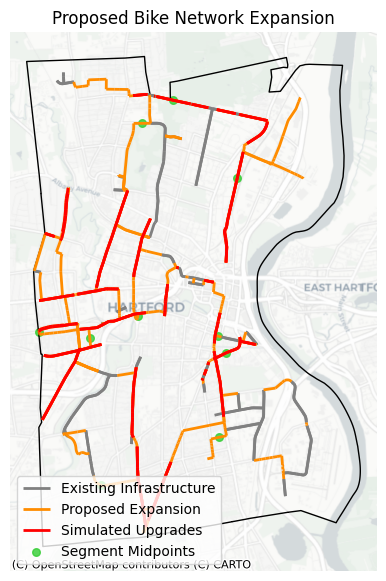

In [ ]:
upgrade_segments = osm_edges.query("growth_priority == 'simulated_upgrade'").copy()

fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

# Original infrastructure
osm_edges.query(
    "infra_type != 'none' and stress_final == 'low' and growth_priority != 'simulated_upgrade'"
).plot(
    ax=ax, color="gray", linewidth=2, label="Existing Infrastructure"
)

# Proposed growth links
growth_candidates.plot(
    ax=ax, color="darkorange", linewidth=2, label="Proposed Expansion"
)

# Simulated upgrades (existing infra that needs upgrade)
if not upgrade_segments.empty:
    upgrade_segments.plot(
        ax=ax,
        color="red",
        linewidth=2,
        label="Simulated Upgrades"
    )

# 🟢 Add midpoints
midpoints_4 = midpoints_gdf_4.copy()
midpoints_4 = midpoints_4.to_crs(study_crs)
midpoints_4.plot(
    ax=ax,
    color="limegreen",
    markersize=30,
    alpha=0.8,
    label="Segment Midpoints"
)

study_area_poly.plot(ax=ax, edgecolor="black", facecolor="none")
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title("Proposed Bike Network Expansion")
ax.legend(loc="lower left")
save_fig(fig, os.path.join(results_fp, "bike_network_growth_midpoints"))


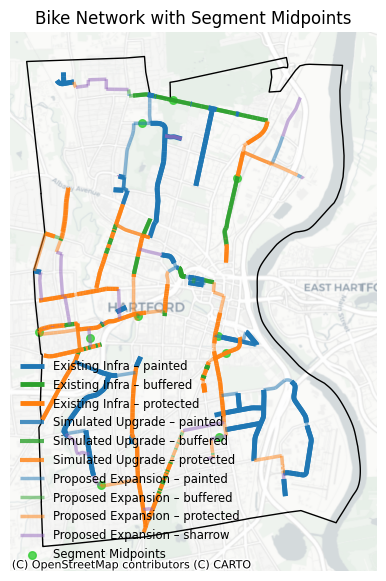

In [ ]:
# Existing plotting setup
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

def plot_with_alpha_and_width(df, label_prefix, alpha, linewidth):
    for infra_type, color in pdict["infra_colors"].items():
        subset = df.query(f"ideal_infra == '{infra_type}'")
        if not subset.empty:
            subset.plot(
                ax=ax,
                color=color,
                linewidth=linewidth,
                linestyle="solid",
                alpha=alpha,
                label=f"{label_prefix} – {infra_type}"
            )

# Existing infra (bold line)
plot_with_alpha_and_width(
    osm_edges.query("infra_type != 'none' and stress_final == 'low' and growth_priority != 'simulated_upgrade'"),
    "Existing Infra", alpha=1.0, linewidth=3.5
)

# Simulated upgrades (medium line)
plot_with_alpha_and_width(
    osm_edges.query("growth_priority == 'simulated_upgrade'"),
    "Simulated Upgrade", alpha=0.8, linewidth=3
)

# Proposed expansion (lighter line)
plot_with_alpha_and_width(
    growth_candidates.query("growth_priority == 'MST_corridor'"),
    "Proposed Expansion", alpha=0.5, linewidth=2.5
)

# 🟢 Add midpoints
midpoints_4.plot(
    ax=ax,
    color="limegreen",
    markersize=30,
    alpha=0.8,
    label="Segment Midpoints"
)

# Background map and layout
study_area_poly.plot(ax=ax, edgecolor="black", facecolor="none")
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title("Bike Network with Segment Midpoints")
ax.legend(loc="lower left", fontsize="small", frameon=False)

# Save the figure
save_fig(fig, os.path.join(results_fp, "bike_network_with_midpoints"))

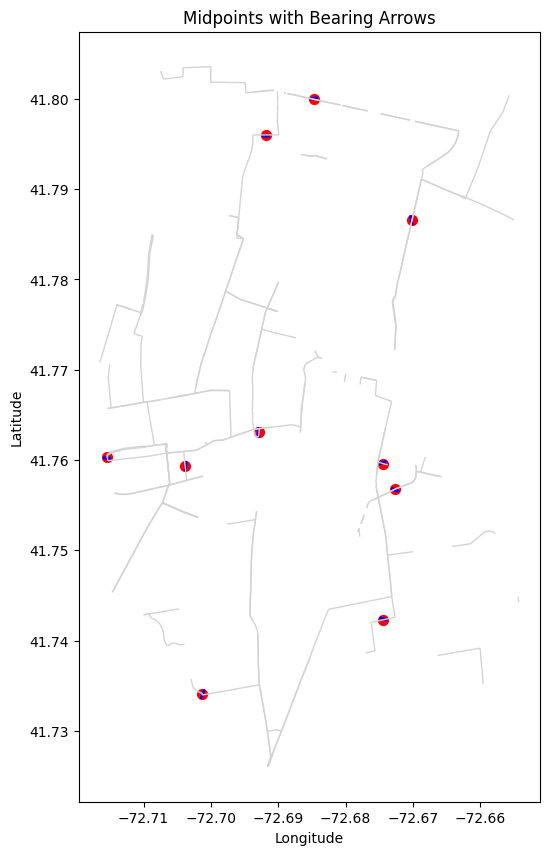

In [ ]:
def plot_bearing_arrow(row, ax, length=0.0002):
    angle_rad = math.radians(row["bearing"])
    dx = length * math.cos(angle_rad)  # longitude (x)
    dy = length * math.sin(angle_rad)  # latitude (y)
    ax.arrow(row["x"], row["y"], dx, dy, head_width=0.00005, color="blue")


# Plot base map
fig, ax = plt.subplots(figsize=(10, 10))
gc.plot(ax=ax, color="lightgray", linewidth=1)
midpoints_gdf_4.plot(ax=ax, color="red", markersize=50)

# Add arrows for bearings
midpoints_gdf_4.apply(lambda row: plot_bearing_arrow(row, ax), axis=1)

plt.title("Midpoints with Bearing Arrows")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()


In [ ]:
import hashlib
import requests
from datetime import datetime
import glob

def get_hash_key(lat, lng, heading, fov=90, pitch=0, size="300x200"):
    key_string = f"{lat}_{lng}_{heading}_{fov}_{pitch}_{size}"
    return hashlib.md5(key_string.encode()).hexdigest()

def find_cached_image(hash_key):
    pattern = os.path.join(images_fp, f"{hash_key}_*.jpg")
    matches = glob.glob(pattern)
    return matches[0] if matches else None

def get_timestamped_filename(hash_key):
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    return os.path.join(images_fp, f"{hash_key}_{timestamp}.jpg")


def download_image_if_needed(url, hash_key):
    cached_file = find_cached_image(hash_key)
    if cached_file:
        print(f"Using cached image: {cached_file}")
        return cached_file

    filename = get_timestamped_filename(hash_key)
    response = requests.get(url)
    if response.status_code == 200:
        with open(filename, "wb") as f:
            f.write(response.content)
        print(f"Image saved: {filename}")
        return filename
    else:
        print(f"Failed to download image: {url} (Status code: {response.status_code})")
        return None

In [ ]:
rows4 = []
for _, row in midpoints_gdf_4.iterrows():
    lat = row["y"]
    lng = row["x"]
    heading = row["bearing"]
    street = row["street_name"]

    url = build_streetview_url(lat, lng, heading, API_KEY)
    hash_key = get_hash_key(lat, lng, heading)

    image_path = download_image_if_needed(url, hash_key)
    if image_path:
        rows4.append({
            "Street": street,
            "Direction": f'<img src="{os.path.abspath(image_path)}" width="300">'
        })

df_images4 = pd.DataFrame(rows4)

Using cached image: /content/drive/MyDrive/bike_net_tool/hartford_4/results/images/14460a1d4e20f4780bce7b5b0959bbbb_20250820_205908.jpg
Using cached image: /content/drive/MyDrive/bike_net_tool/hartford_4/results/images/f68e78c64573517f699ce274246e3f95_20250820_205909.jpg
Using cached image: /content/drive/MyDrive/bike_net_tool/hartford_4/results/images/a5288d5b0f5daba2fa0aa473ba84007e_20250820_205909.jpg
Using cached image: /content/drive/MyDrive/bike_net_tool/hartford_4/results/images/1cbd170b0d625b4b04a13943210cbe5d_20250820_205909.jpg
Using cached image: /content/drive/MyDrive/bike_net_tool/hartford_4/results/images/a48853365b5922904a609260a2bb00a6_20250820_205909.jpg
Using cached image: /content/drive/MyDrive/bike_net_tool/hartford_4/results/images/c912fcc5b9df30cfe87fef6f4c85ce87_20250820_205909.jpg
Using cached image: /content/drive/MyDrive/bike_net_tool/hartford_4/results/images/68f03d105cc9fbc43a7581d45b47bf69_20250820_205910.jpg
Using cached image: /content/drive/MyDrive/bike_

Orange Street


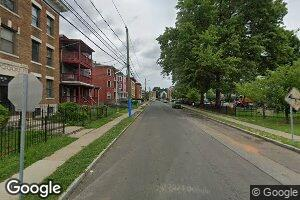

Harvard Street


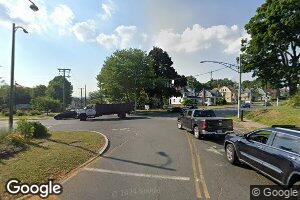

Windsor Street


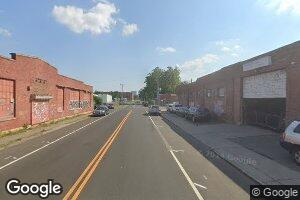

Charter Oak Avenue


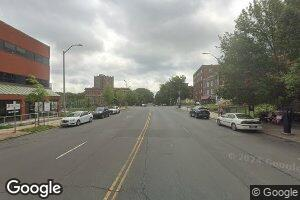

Wyllys Street


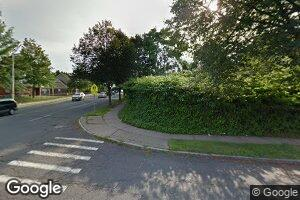

Tower Avenue


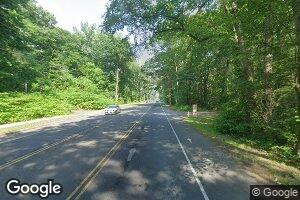

Park Terrace


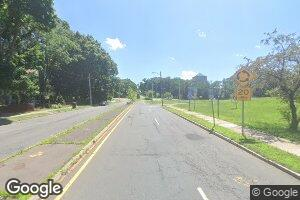

Holcomb Street


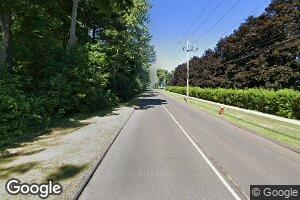

Boulevard


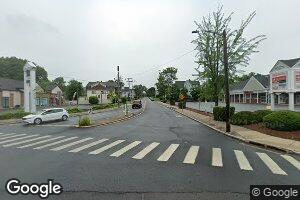

Adelaide Street


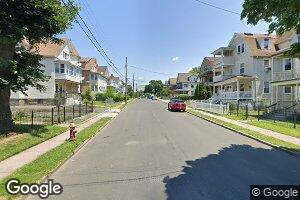

In [ ]:
for _, row in df_images4.iterrows():
    print(row["Street"])
    display(Image(filename=row["Direction"].split('"')[1].replace("file://", "")))

# **Connectivity to Locations**

In [ ]:
# Define OSM tags for each category
CATEGORY_TAGS = {
    'core_services': {
        'shop': ['convenience']
    },
    'opportunity': {
        'amenity': ['library']
    },
    'recreation': {
        'leisure': ['park']
    }
}

In [ ]:
# Build precise tag filter
tags = {}
for tag_dict in CATEGORY_TAGS.values():
    for key, values in tag_dict.items():
        tags.setdefault(key, []).extend(values)

# Define osm_keys from the tag filter
osm_keys = list(tags.keys())

# Keep all geometries initially
pois_all = ox.features_from_polygon(study_geom_wgs, tags)

# Convert non-point geometries to centroids
pois_all['geometry'] = pois_all.geometry.centroid

# Now proceed with your tag filtering and counting
pois = pois_all.copy()

# Ensure all expected OSM keys are present as columns
for key in osm_keys:
    if key not in pois.columns:
        pois[key] = None

# Reproject to your study CRS
pois = pois.to_crs(study_crs)

In [ ]:
from collections import Counter, defaultdict

# Initialize a dictionary to hold counts for each category
category_counts = defaultdict(Counter)

# Loop through each category and its tags
for category, tag_dict in CATEGORY_TAGS.items():
    for key, values in tag_dict.items():
        for value in values:
            # Count how many times each tag appears in the pois GeoDataFrame
            count = pois[pois[key] == value].shape[0]
            category_counts[category][f"{key}:{value}"] = count

# Display the counts
for category, counts in category_counts.items():
    print(f"\nCategory: {category}")
    for tag, count in counts.items():
        print(f"  {tag}: {count}")

# Optional: Find the mode (most frequent tag) in each category
category_modes = {
    category: counts.most_common(1)[0]  # returns (tag, count)
    for category, counts in category_counts.items()
}

print("\n🏆 Most Common Tag in Each Category:")
for category, (tag, count) in category_modes.items():
    print(f"{category}: {tag} ({count} occurrences)")


Category: core_services
  shop:convenience: 13

Category: opportunity
  amenity:library: 16

Category: recreation
  leisure:park: 66

🏆 Most Common Tag in Each Category:
core_services: shop:convenience (13 occurrences)
opportunity: amenity:library (16 occurrences)
recreation: leisure:park (66 occurrences)


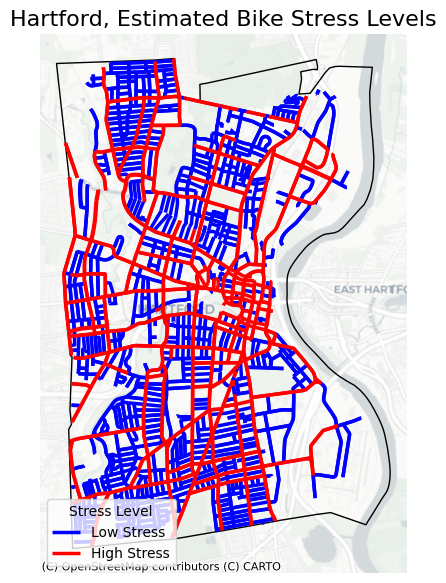

In [ ]:
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

for stress_level, style in pdict["stress_styles"].items():
    subset = osm_edges.query(f"stress_init == '{stress_level}'")
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=style["color"],
            linewidth=style["linewidth"],
            linestyle=style["linestyle"],
            label=style["label"]
        )

study_area_poly.plot(ax=ax, edgecolor=pdict["base"], facecolor="none", linewidth=1)
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title(f"{area_name}, Estimated Bike Stress Levels", fontsize=16)
ax.legend(title="Stress Level", loc="lower left")
save_fig(fig, os.path.join(results_fp, "bike_stress_levels"))

In [ ]:
# Step 1: Create a set of osmids from growth_candidates
growth_ids = set(growth_candidates['osmid'])

# Step 2: Update stress_final in osm_edges
osm_edges['stress_final'] = osm_edges.apply(
    lambda row: 'low' if row['osmid'] in growth_ids else row['stress_final'],
    axis=1
)

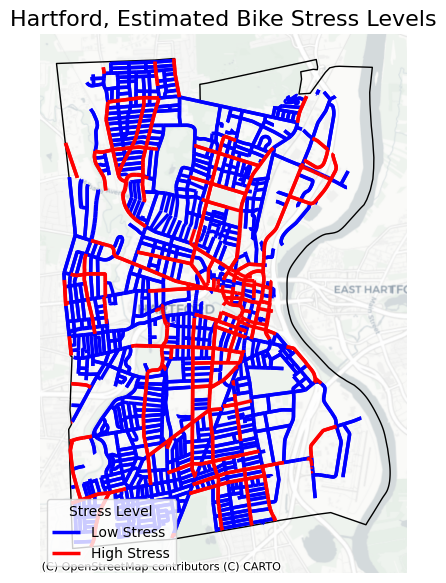

In [ ]:
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

for stress_level, style in pdict["stress_styles"].items():
    subset = osm_edges.query(f"stress_final == '{stress_level}'")
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=style["color"],
            linewidth=style["linewidth"],
            linestyle=style["linestyle"],
            label=style["label"]
        )

study_area_poly.plot(ax=ax, edgecolor=pdict["base"], facecolor="none", linewidth=1)
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

ax.set_axis_off()
ax.set_title(f"{area_name}, Estimated Bike Stress Levels", fontsize=16)
ax.legend(title="Stress Level", loc="lower left")
save_fig(fig, os.path.join(results_fp, "bike_stress_levels_final"))

In [ ]:
# Check CRS of all layers
print("Residential zones CRS:", residential_zones.crs)
print("Existing network CRS:", osm_edges.crs)
print("POIs CRS:", pois.crs)


Residential zones CRS: EPSG:26956
Existing network CRS: EPSG:26956
POIs CRS: EPSG:26956


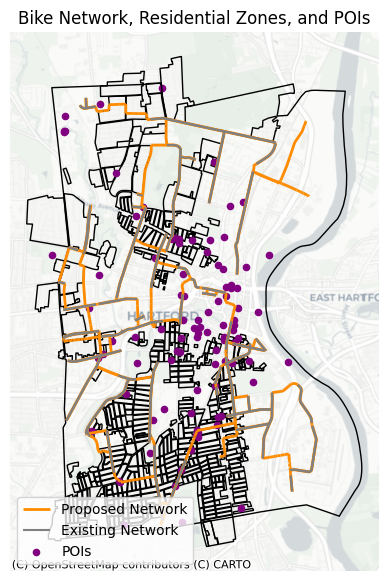

In [ ]:
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])


# Proposed network expansion
proposed_edges.plot(ax=ax, color="darkorange", linewidth=2, label="Proposed Network")

# Existing bike network
existing_all.plot(ax=ax, color="gray", linewidth=1.5, label="Existing Network")

# Residential zones
residential_zones.plot(ax=ax, edgecolor="black", facecolor="none", linewidth=1, label="Residential Zones")

# POIs (all types)
pois.plot(ax=ax, color="purple", markersize=20, label="POIs")

# Basemap
study_area_poly.plot(ax=ax, edgecolor="black", facecolor="none")
cx.add_basemap(ax=ax, crs=study_area_poly.crs, source=pdict["basemap_primary"])

# Final touches
ax.set_axis_off()
ax.set_title("Bike Network, Residential Zones, and POIs")
ax.legend(loc="lower left")

# Save figure
save_fig(fig, os.path.join(results_fp, "network_zones_pois_map"))


In [ ]:

low_stress_nodes = extract_nodes_from_edges(init_low_stress, osm_nodes)
low_stress_nodes = low_stress_nodes.set_index("osmid")

G = ox.graph_from_gdfs(low_stress_nodes, init_low_stress)

residential_zones['centroid'] = residential_zones.geometry.centroid
centroids = residential_zones.set_geometry('centroid')

centroid_nodes = ox.distance.nearest_nodes(G, X=centroids.geometry.x, Y=centroids.geometry.y)

zone_graph = nx.Graph()

for i, node_i in enumerate(centroid_nodes):
    for j, node_j in enumerate(centroid_nodes):
        if i >= j:
            continue
        try:
            # If a path exists, connect the zones
            nx.shortest_path_length(G, node_i, node_j, weight='length')
            zone_graph.add_edge(i, j)
        except nx.NetworkXNoPath:
            continue

components = list(nx.connected_components(zone_graph))

merged_geoms = []
for comp in components:
    zones = residential_zones.iloc[list(comp)]
    merged_geom = unary_union(zones.geometry)
    merged_geoms.append(merged_geom)

# Create GeoDataFrame of merged zones
merged_zones = gpd.GeoDataFrame(geometry=merged_geoms, crs=residential_zones.crs)
merged_zones['centroid'] = merged_zones.geometry.centroid


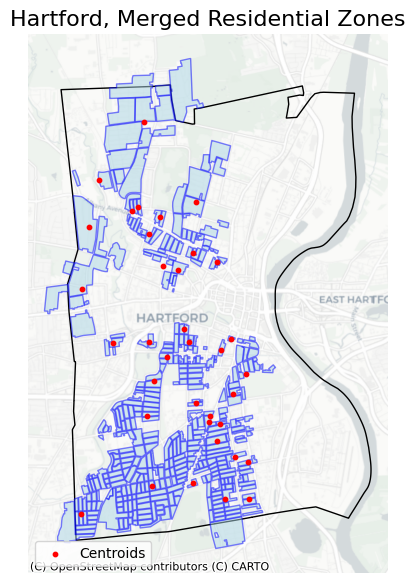

In [ ]:
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

# Plot base study area
study_area_poly.plot(ax=ax, edgecolor=pdict["base"], facecolor="none", linewidth=1)

# Plot merged zones
merged_zones.plot(ax=ax, color='lightblue', edgecolor='blue', alpha=0.5, linewidth=1, label='Merged Zones')

# Plot centroids
merged_zones.set_geometry('centroid').plot(ax=ax, color='red', markersize=10, label='Centroids')

# Add basemap
cx.add_basemap(ax=ax, crs=merged_zones.crs, source=pdict["basemap_primary"])

# Style the plot
ax.set_axis_off()
ax.set_title(f"{area_name}, Merged Residential Zones", fontsize=16)
ax.legend(loc="lower left")

# Save the figure
save_fig(fig, os.path.join(results_fp, "merged_zones_map"))


In [ ]:
# Step 2: Map merged zone centroids to graph nodes
centroid_nodes = ox.distance.nearest_nodes(G,
                                           X=merged_zones['centroid'].x,
                                           Y=merged_zones['centroid'].y)

# Step 3: Map POIs to graph nodes
poi_nodes = ox.distance.nearest_nodes(G,
                                      X=pois.geometry.x,
                                      Y=pois.geometry.y)

# Step 4: Count reachable POIs for each centroid
reachable_counts = []

for node in centroid_nodes:
    # Get all nodes within 2680m from this centroid node
    reachable = nx.single_source_dijkstra_path_length(G, node, cutoff=2680, weight='length')
    reachable_set = set(reachable.keys())

    # Count how many POIs are in that reachable set
    count = sum(1 for poi_node in poi_nodes if poi_node in reachable_set)
    reachable_counts.append(count)

# Step 5: Store results
merged_zones['reachable_pois'] = reachable_counts


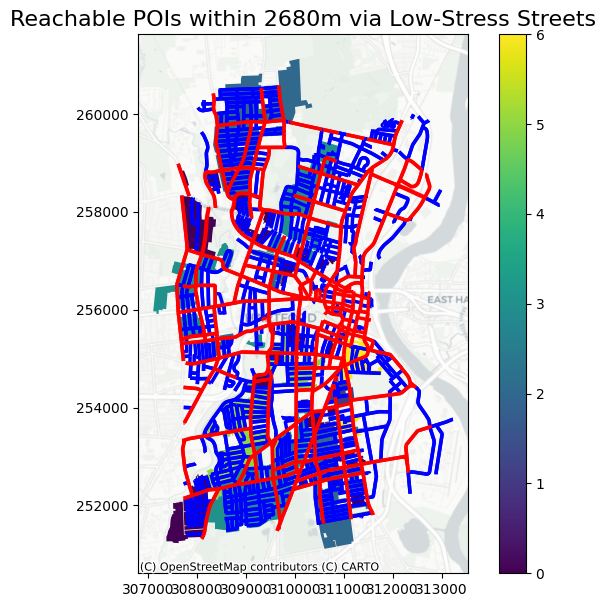

In [ ]:
fig, ax = plt.subplots(1, figsize=pdict["fsmap"])

for stress_level, style in pdict["stress_styles"].items():
    subset = osm_edges.query(f"stress_init == '{stress_level}'")
    if not subset.empty:
        subset.plot(
            ax=ax,
            color=style["color"],
            linewidth=style["linewidth"],
            linestyle=style["linestyle"],
            label=style["label"]
        )

merged_zones.plot(ax=ax, column='reachable_pois', cmap='viridis', legend=True)
cx.add_basemap(ax=ax, crs=merged_zones.crs, source=pdict["basemap_primary"])
ax.set_title("Reachable POIs within 2680m via Low-Stress Streets", fontsize=16)
save_fig(fig, os.path.join(results_fp, "reachable_pois_map"))


In [ ]:
# Step 1: Map merged zone centroids to graph nodes
centroid_nodes = ox.distance.nearest_nodes(G,
                                           X=merged_zones['centroid'].x,
                                           Y=merged_zones['centroid'].y)

# Step 2: Map POIs to graph nodes
poi_nodes = ox.distance.nearest_nodes(G,
                                      X=pois.geometry.x,
                                      Y=pois.geometry.y)

# Step 3: Precompute POI categories per node
poi_category_map = {}  # node_id -> set of categories

for i, poi in enumerate(pois.itertuples()):
    node = poi_nodes[i]  # Access by position, not index
    categories = set()
    for category, tag_dict in CATEGORY_TAGS.items():
        match = True
        for key, values in tag_dict.items():
            if getattr(poi, key, None) not in values:
                match = False
        if match:
            categories.add(category)
    poi_category_map.setdefault(node, set()).update(categories)

# Step 4: Count reachable POIs per category for each merged zone
category_names = list(CATEGORY_TAGS.keys())
for category in category_names:
    merged_zones[category + '_count'] = 0

for i, node in enumerate(centroid_nodes):
    reachable = nx.single_source_dijkstra_path_length(G, node, cutoff=2680, weight='length')
    reachable_nodes = set(reachable.keys())

    # Initialize counters
    counts = {cat: 0 for cat in category_names}

    # Count POIs by category
    for poi_node, categories in poi_category_map.items():
        if poi_node in reachable_nodes:
            for cat in categories:
                counts[cat] += 1

    # Store counts in merged_zones
    for cat in category_names:
        merged_zones.at[i, cat + '_count'] = counts[cat]


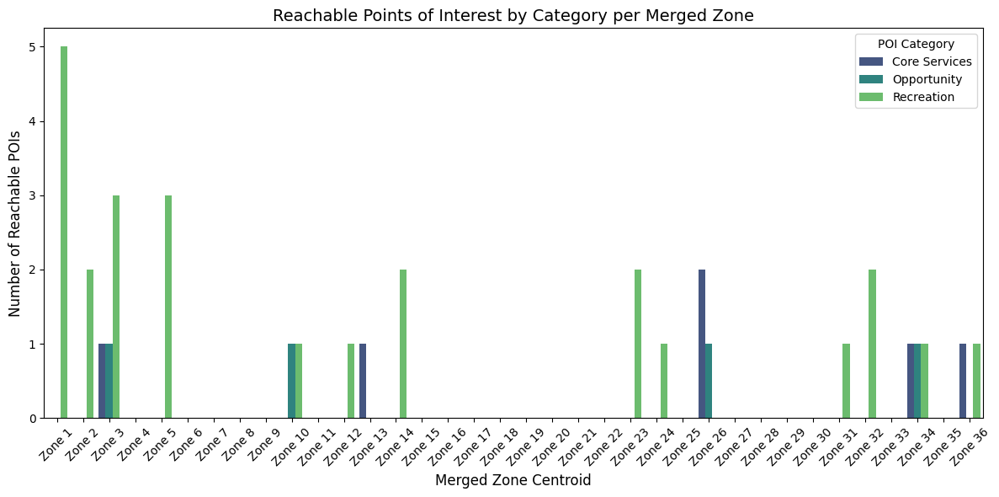

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Optional: assign a unique ID or name to each zone if not already present
if 'zone_id' not in merged_zones.columns:
    merged_zones['zone_id'] = [f"Zone {i+1}" for i in range(len(merged_zones))]

# Reshape the data for plotting
melted_df = merged_zones.melt(
    id_vars='zone_id',
    value_vars=['core_services_count', 'opportunity_count', 'recreation_count'],
    var_name='Category',
    value_name='Count'
)

# Rename categories for readability
category_labels = {
    'core_services_count': 'Core Services',
    'opportunity_count': 'Opportunity',
    'recreation_count': 'Recreation'
}
melted_df['Category'] = melted_df['Category'].map(category_labels)

# Plot
plt.figure(figsize=(12, 6))
sns.barplot(data=melted_df, x='zone_id', y='Count', hue='Category', palette='viridis')

plt.title('Reachable Points of Interest by Category per Merged Zone', fontsize=14)
plt.xlabel('Merged Zone Centroid', fontsize=12)
plt.ylabel('Number of Reachable POIs', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='POI Category')
plt.tight_layout()
plt.show()

In [ ]:
# Step 1: Concatenate edge sets
final_low_stress = osm_edges[osm_edges['stress_final'] == 'low']

In [ ]:
# Step 6: Ensure unique node index
final_low_stress_nodes = extract_nodes_from_edges(final_low_stress, osm_nodes)

In [ ]:
final_low_stress_nodes = final_low_stress_nodes.set_index("osmid")

In [ ]:
G_final = ox.graph_from_gdfs(final_low_stress_nodes, final_low_stress)

centroid_nodes_final = ox.distance.nearest_nodes(
    G_final,
    X=merged_zones['centroid'].x,
    Y=merged_zones['centroid'].y
)

poi_nodes_final = ox.distance.nearest_nodes(
    G_final,
    X=pois.geometry.x,
    Y=pois.geometry.y
)

reachable_counts_final = []

for node in centroid_nodes_final:
    reachable = nx.single_source_dijkstra_path_length(G_final, node, cutoff=2680, weight='length')
    reachable_set = set(reachable.keys())

    count = sum(1 for poi_node in poi_nodes_final if poi_node in reachable_set)
    reachable_counts_final.append(count)

merged_zones['reachable_pois_final'] = reachable_counts_final

# Precompute POI categories per node
poi_category_map_final = {}

for i, poi in enumerate(pois.itertuples()):
    node = poi_nodes_final[i]
    categories = set()
    for category, tag_dict in CATEGORY_TAGS.items():
        match = True
        for key, values in tag_dict.items():
            if getattr(poi, key, None) not in values:
                match = False
        if match:
            categories.add(category)
    poi_category_map_final.setdefault(node, set()).update(categories)

# Initialize new columns
for category in CATEGORY_TAGS.keys():
    merged_zones[category + '_count_final'] = 0

# Count per category
for i, node in enumerate(centroid_nodes_final):
    reachable = nx.single_source_dijkstra_path_length(G_final, node, cutoff=2680, weight='length')
    reachable_nodes = set(reachable.keys())

    counts = {cat: 0 for cat in CATEGORY_TAGS.keys()}

    for poi_node, categories in poi_category_map_final.items():
        if poi_node in reachable_nodes:
            for cat in categories:
                counts[cat] += 1

    for cat in CATEGORY_TAGS.keys():
        merged_zones.at[i, cat + '_count_final'] = counts[cat]


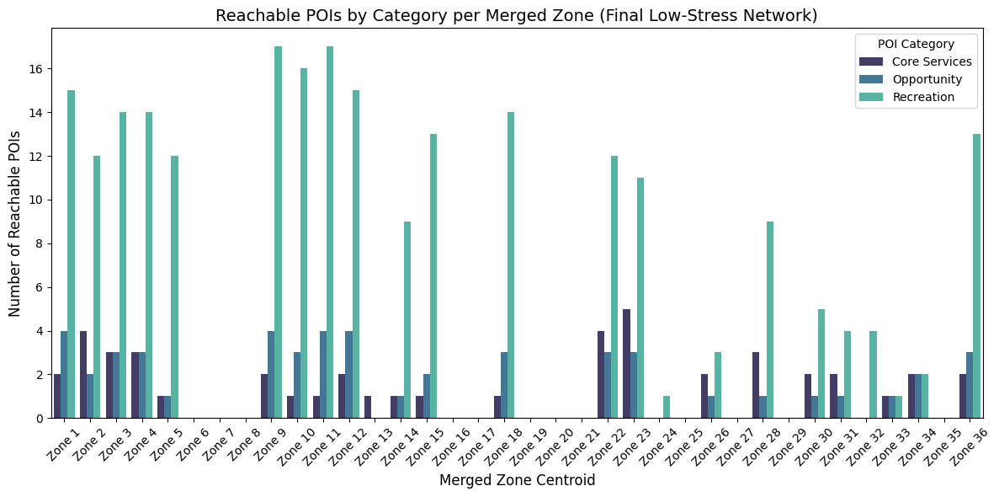

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Optional: assign a unique ID or name to each zone if not already present
if 'zone_id' not in merged_zones.columns:
    merged_zones['zone_id'] = [f"Zone {i+1}" for i in range(len(merged_zones))]

# Reshape the data for plotting (final counts)
melted_final_df = merged_zones.melt(
    id_vars='zone_id',
    value_vars=['core_services_count_final', 'opportunity_count_final', 'recreation_count_final'],
    var_name='Category',
    value_name='Count'
)

# Rename categories for readability
category_labels_final = {
    'core_services_count_final': 'Core Services',
    'opportunity_count_final': 'Opportunity',
    'recreation_count_final': 'Recreation'
}
melted_final_df['Category'] = melted_final_df['Category'].map(category_labels_final)

# Plot
plt.figure(figsize=(12, 6))
sns.barplot(data=melted_final_df, x='zone_id', y='Count', hue='Category', palette='mako')

plt.title('Reachable POIs by Category per Merged Zone (Final Low-Stress Network)', fontsize=14)
plt.xlabel('Merged Zone Centroid', fontsize=12)
plt.ylabel('Number of Reachable POIs', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='POI Category')
plt.tight_layout()
plt.show()


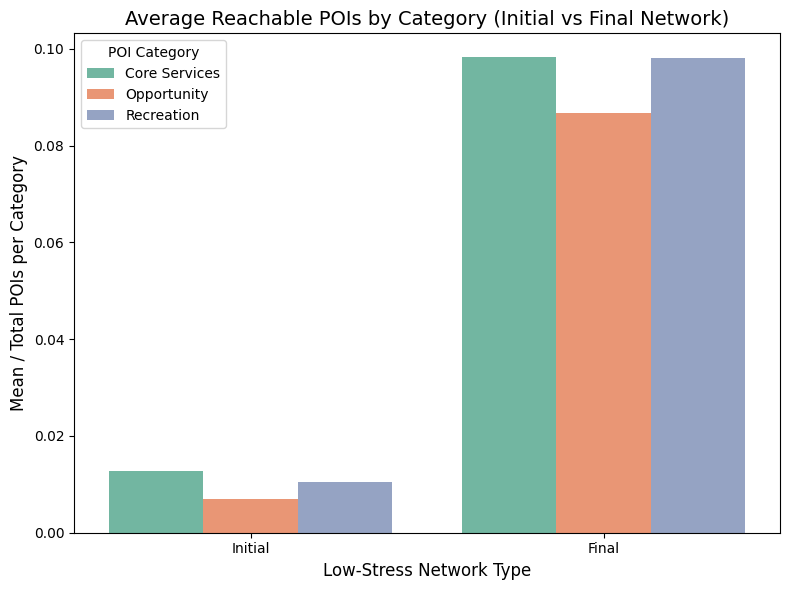

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Compute normalized average counts per category
avg_init = {
    'Core Services': merged_zones['core_services_count'].mean() / category_counts['core_services']['shop:convenience'],
    'Opportunity': merged_zones['opportunity_count'].mean() / category_counts['opportunity']['amenity:library'],
    'Recreation': merged_zones['recreation_count'].mean() / category_counts['recreation']['leisure:park']
}

avg_final = {
    'Core Services': merged_zones['core_services_count_final'].mean() / category_counts['core_services']['shop:convenience'],
    'Opportunity': merged_zones['opportunity_count_final'].mean() / category_counts['opportunity']['amenity:library'],
    'Recreation': merged_zones['recreation_count_final'].mean() / category_counts['recreation']['leisure:park']
}


# Step 2: Create tidy DataFrame for plotting
summary_df = pd.DataFrame([
    {'Network': 'Initial', 'Category': cat, 'Average Count': avg_init[cat]} for cat in avg_init
] + [
    {'Network': 'Final', 'Category': cat, 'Average Count': avg_final[cat]} for cat in avg_final
])

# Step 3: Plot grouped bar chart
plt.figure(figsize=(8, 6))
sns.barplot(data=summary_df, x='Network', y='Average Count', hue='Category', palette='Set2')

plt.title('Average Reachable POIs by Category (Initial vs Final Network)', fontsize=14)
plt.ylabel('Mean / Total POIs per Category', fontsize=12)
plt.xlabel('Low-Stress Network Type', fontsize=12)
plt.legend(title='POI Category')
plt.tight_layout()
plt.show()
